## **BAB 1: Objektif Bisnis**

Membantu otoritas pangan Italia mengantisipasi pergerakan harga rata-rata 
komoditas (Fruit, Vegetable, Meat) secara nasional untuk 6 bulan ke depan, 
sehingga kebijakan intervensi seperti subsidi atau stabilisasi harga dapat 
disiapkan lebih awal.

**Pengguna:** Pembuat kebijakan pangan Italia  
**Kriteria sukses:** MAPE < 5%

##  **BAB 2 - Tujuan Teknis Data Science**

- **Tipe masalah:** Time Series Forecasting
- **Target variabel:** Harga rata-rata mingguan per kategori (Fruit, Vegetable, Meat)
- **Horizon forecast:** 180 hari ke depan (~6 bulan)
- **Model:** ARIMA, SARIMA, Linear Regression, Decision Tree, XGBoost
- **Pendekatan:** 3 model terpisah per kategori, recursive forecasting untuk model ML

**Fitur (khusus model ML):**
- Lag features: lag-1, lag-2, lag-3, lag-4, lag-5, lag-6, lag-7, rolling mean 7 hari
- Calendar features: minggu, bulan, kuartal, musim

**Kriteria sukses teknis:**
| MAPE | Interpretasi |
|---|---|
| < 5% | Layak sebagai basis kebijakan utama |
| 5–10% | Layak sebagai referensi pendukung |
| > 10% | Perlu revisit model |

**Metrik pendukung:** MAE, RMSE

In [1]:
import os
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pmdarima import auto_arima
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeRegressor
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')

In [2]:
HORIZON = 182  # hari (6 bulan)
CATEGORIES = ['Fruit', 'Vegetable', 'Meat']
COLORS = ['#2ecc71', '#27ae60', '#e74c3c']
FEATURES = ['lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7',
            'rolling_mean_7',
            'day_of_week', 'day_of_month', 'month', 'quarter', 'season']
SEASON_MAP = {12: 0, 1: 0, 2: 0,
               3: 1, 4: 1, 5: 1,
               6: 2, 7: 2, 8: 2,
               9: 3, 10: 3, 11: 3}

In [3]:
def split_train_test(data, horizon=HORIZON):
    """Membagi data menjadi train dan test set berdasarkan horizon."""
    train = data.iloc[:-horizon].copy()
    test = data.iloc[-horizon:].copy()
    return train, test


def scale_data(train, test):
    """Menerapkan MinMaxScaler; fit hanya pada train, transform keduanya."""
    scaler = MinMaxScaler()
    train_scaled = train.copy()
    test_scaled = test.copy()
    train_scaled['avg_price'] = scaler.fit_transform(train[['avg_price']])
    test_scaled['avg_price'] = scaler.transform(test[['avg_price']])
    return train_scaled, test_scaled, scaler


def create_features(data, lags=[1, 2, 3, 4, 5, 6, 7]):
    """Membuat lag, rolling mean, dan calendar features pada data."""
    df = data.copy()
    for lag in lags:
        df[f'lag_{lag}'] = df['avg_price'].shift(lag)
    df['rolling_mean_7'] = df['avg_price'].shift(1).rolling(window=7).mean()
    df['day_of_week'] = df['day'].dt.dayofweek      # fitur baru
    df['day_of_month'] = df['day'].dt.day           # fitur baru
    df['month'] = df['day'].dt.month
    df['quarter'] = df['day'].dt.quarter
    df['season'] = df['month'].map(SEASON_MAP)
    df = df.dropna().reset_index(drop=True)
    return df


def create_features_train_test(train, test, lags=[1, 2, 3, 4, 5, 6, 7]):
    """Membuat features pada gabungan train+test lalu split kembali."""
    combined = pd.concat([train, test], axis=0).reset_index(drop=True)
    combined = create_features(combined, lags)
    train_out = combined.iloc[:-HORIZON].copy()
    test_out = combined.iloc[-HORIZON:].copy()
    return train_out, test_out


def evaluate(actual, predicted, label=''):
    """Menghitung MAE, RMSE, dan MAPE; mencetak hasilnya."""
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100
    print(f"{label}")
    print(f"  MAE  : {mae:.4f}")
    print(f"  RMSE : {rmse:.4f}")
    print(f"  MAPE : {mape:.2f}%")
    return {'MAE': mae, 'RMSE': rmse, 'MAPE': mape}


def plot_forecast(train, test, predicted, title=''):
    """Memplot data train, aktual test, dan prediksi forecast."""
    plt.figure(figsize=(14, 4))
    plt.plot(train['day'], train['avg_price'],
             label='Train', color='gray', linewidth=1)
    plt.plot(test['day'], test['avg_price'],
             label='Aktual', color='blue', linewidth=1.5)
    plt.plot(test['day'], predicted,
             label='Forecast', color='red', linewidth=1.5, linestyle='--')
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


def recursive_forecast(model, test_fe, train_fe, scaler, horizon=HORIZON):
    """Melakukan recursive forecasting: prediksi step-by-step menggunakan lag dari prediksi sebelumnya."""
    predictions_scaled = []
    history = train_fe['avg_price'].tolist()

    for i in range(horizon):
        row = test_fe.iloc[i].copy()
        for lag in [1, 2, 3, 4, 5, 6, 7]:
            if len(history) >= lag:
                row[f'lag_{lag}'] = history[-lag]
        row['rolling_mean_7'] = np.mean(history[-7:]) if len(history) >= 7 else np.mean(history)

        X = row[FEATURES].values.reshape(1, -1)
        pred_scaled = model.predict(X)[0]
        predictions_scaled.append(pred_scaled)
        history.append(pred_scaled)

    predictions = scaler.inverse_transform(
        np.array(predictions_scaled).reshape(-1, 1)).flatten()
    return predictions


def deploy_forecast(df_cat, model, scaler, horizon=HORIZON):
    """Melakukan deployment forecast ke depan menggunakan seluruh data historis."""
    df = df_cat.copy()
    df['avg_price'] = scaler.transform(df[['avg_price']])
    df_feat = create_features(df)

    model.fit(df_feat[FEATURES], df_feat['avg_price'])

    last_date = df_cat['day'].max()
    future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1),
                                 periods=horizon, freq='D')

    history = df_feat['avg_price'].tolist()
    preds = []

    for future_date in future_dates:
        row = {
            'lag_1': history[-1],
            'lag_2': history[-2],
            'lag_3': history[-3],
            'lag_4': history[-4],  
            'lag_5': history[-5],  
            'lag_6': history[-6],
            'lag_7': history[-7],        
            'rolling_mean_7': np.mean(history[-7:]), 
            'day_of_week': future_date.dayofweek,
            'day_of_month': future_date.day,
            'month': future_date.month,
            'quarter': future_date.quarter,
            'season': SEASON_MAP[future_date.month]
        }
        X = np.array([row[f] for f in FEATURES]).reshape(1, -1)
        pred = model.predict(X)[0]
        preds.append(pred)
        history.append(pred)

    preds_actual = scaler.inverse_transform(
        np.array(preds).reshape(-1, 1)).flatten()
    return pd.DataFrame({'day': future_dates, 'forecast': preds_actual.round(4)})


def fit_full_data(df_cat, model, scaler):
    """Fit model pada seluruh data (untuk deployment)."""
    df = df_cat.copy()
    df['avg_price'] = scaler.transform(df[['avg_price']])
    df_feat = create_features(df)
    model.fit(df_feat[FEATURES], df_feat['avg_price'])
    return model


## **BAB 3 – Menelaah Data**

In [4]:
# Load data
df = pd.read_csv('Variations_Food_Prices_Italian_Supermarkets.csv')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4033211 entries, 0 to 4033210
Data columns (total 8 columns):
 #   Column      Dtype  
---  ------      -----  
 0   date        object 
 1   price       float64
 2   product_id  int64  
 3   store_id    int64  
 4   region      object 
 5   product     object 
 6   COICOP5     object 
 7   COICOP4     object 
dtypes: float64(1), int64(2), object(5)
memory usage: 246.2+ MB


In [6]:
df.shape

(4033211, 8)

In [7]:
df.dtypes

date           object
price         float64
product_id      int64
store_id        int64
region         object
product        object
COICOP5        object
COICOP4        object
dtype: object

In [8]:
df.head()

,date,price,product_id,store_id,region,product,COICOP5,COICOP4
0,2020-12-03,1.99,2,2,calabria,arance navelina italia calibro 1.5 kg,Oranges,Fruit
1,2020-12-03,2.48,2,3,lazio,arance navelina italia calibro 1.5 kg,Oranges,Fruit
2,2020-12-03,2.49,2,4,calabria,arance navelina italia calibro 1.5 kg,Oranges,Fruit
3,2020-12-03,1.99,2,5,calabria,arance navelina italia calibro 1.5 kg,Oranges,Fruit
4,2020-12-03,2.49,2,8,lazio,arance navelina italia calibro 1.5 kg,Oranges,Fruit


In [9]:
# Konversi date
df['date'] = pd.to_datetime(df['date'])

In [10]:
# Cek rentang waktu
print("Rentang waktu:", df['date'].min(), "→", df['date'].max())
print("Jumlah hari unik:", df['date'].nunique())

Rentang waktu: 2020-12-03 00:00:00 → 2023-04-14 00:00:00
Jumlah hari unik: 841


In [11]:
# Cek nilai unik per kolom kategorik
print("\nJumlah produk unik:", df['product_id'].nunique())
print("Jumlah toko unik:", df['store_id'].nunique())
print("Jumlah region unik:", df['region'].nunique())


Jumlah produk unik: 3138
Jumlah toko unik: 20
Jumlah region unik: 7


In [12]:
print("Kategori COICOP4:\n", df['COICOP4'].value_counts())

Kategori COICOP4:
 COICOP4
Meat         1803639
Fruit        1249599
Vegetable     979973
Name: count, dtype: int64


In [13]:
# Statistik harga per kategori
print("\nStatistik harga per kategori:")
df.groupby('COICOP4')['price'].describe().round(2).T


Statistik harga per kategori:


COICOP4,Fruit,Meat,Vegetable
count,1249599.00,1803639.00,979973.00
mean,2.56,7.58,2.05
std,2.67,7.16,1.00
min,0.49,0.24,0.29
25%,1.00,2.25,1.39
50%,1.99,4.60,1.98
75%,2.98,10.95,2.49
max,29.90,76.80,13.98


In [14]:
# Agregasi harian per kategori
df_daily = (
    df.groupby(['COICOP4', pd.Grouper(key='date', freq='D')])['price']
    .mean()
    .reset_index()
    .rename(columns={'date': 'day', 'price': 'avg_price'})
)

In [15]:
df_daily.shape

(2523, 3)

In [16]:
df_daily.groupby('COICOP4')['day'].count()

COICOP4
Fruit        841
Meat         841
Vegetable    841
Name: day, dtype: int64

In [17]:
df_daily.head(10)

,COICOP4,day,avg_price
0,Fruit,2020-12-03,2.306573
1,Fruit,2020-12-04,2.390705
2,Fruit,2020-12-05,2.393694
3,Fruit,2020-12-06,2.469729
4,Fruit,2020-12-07,2.483297
5,Fruit,2020-12-08,2.451240
6,Fruit,2020-12-09,2.461140
7,Fruit,2020-12-10,2.436159
8,Fruit,2020-12-11,2.398644
9,Fruit,2020-12-12,2.380092


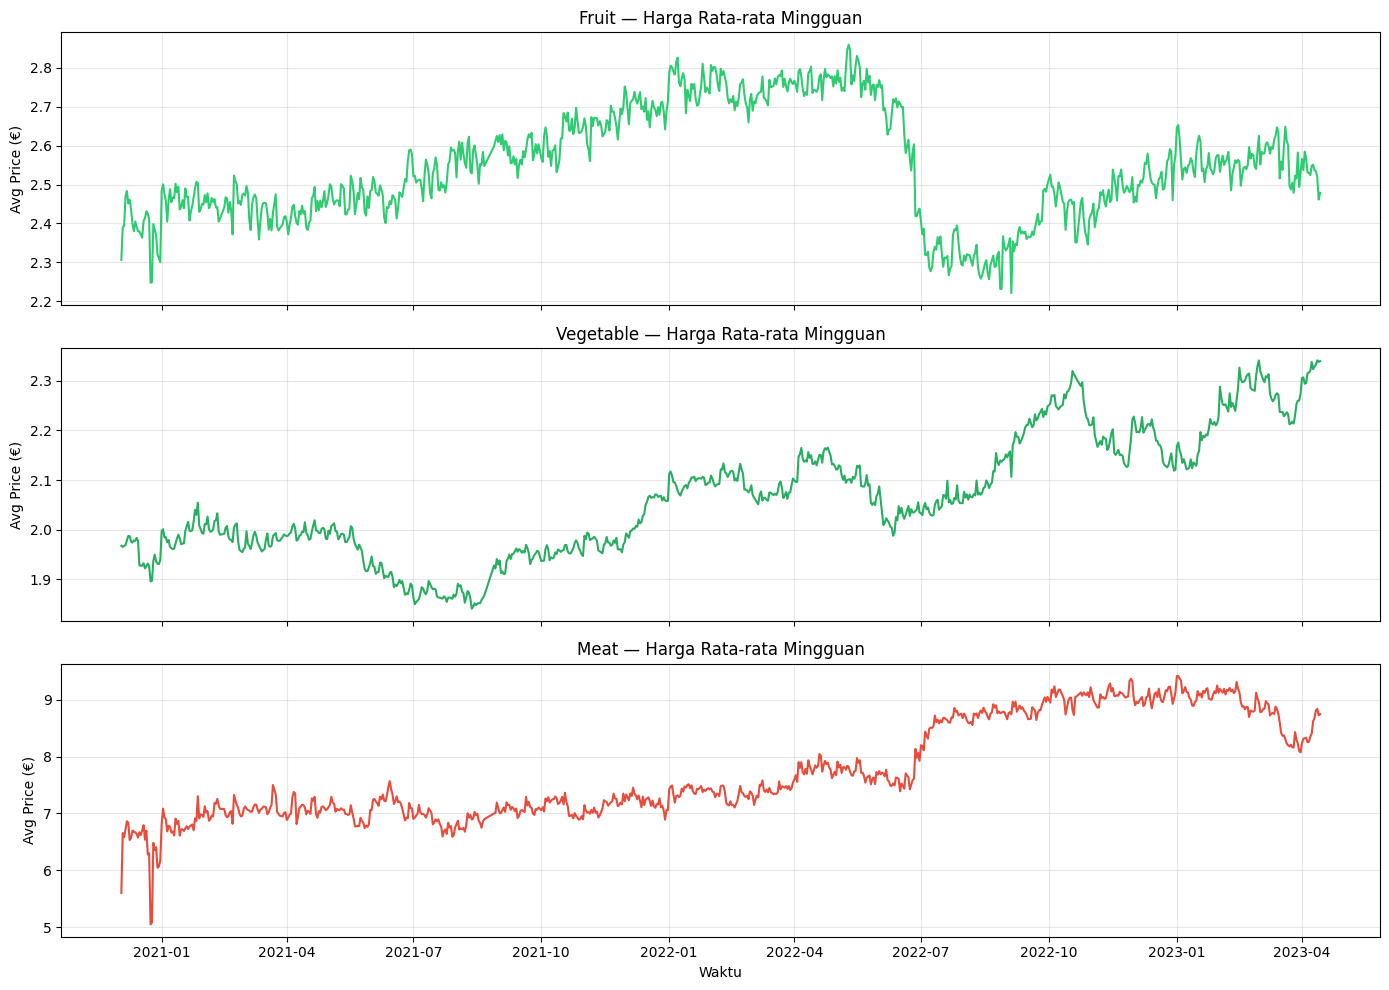

In [ ]:
# Visualisasi tren harga harian
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, cat, color in zip(axes, CATEGORIES, COLORS):
    data = df_daily[df_daily['COICOP4'] == cat]
    ax.plot(data['day'], data['avg_price'], color=color, linewidth=1.5)
    ax.set_title(f'{cat} — Harga Rata-rata Mingguan', fontsize=12)
    ax.set_ylabel('Avg Price (€)')
    ax.grid(True, alpha=0.3)
plt.xlabel('Waktu')
plt.tight_layout()
plt.show()

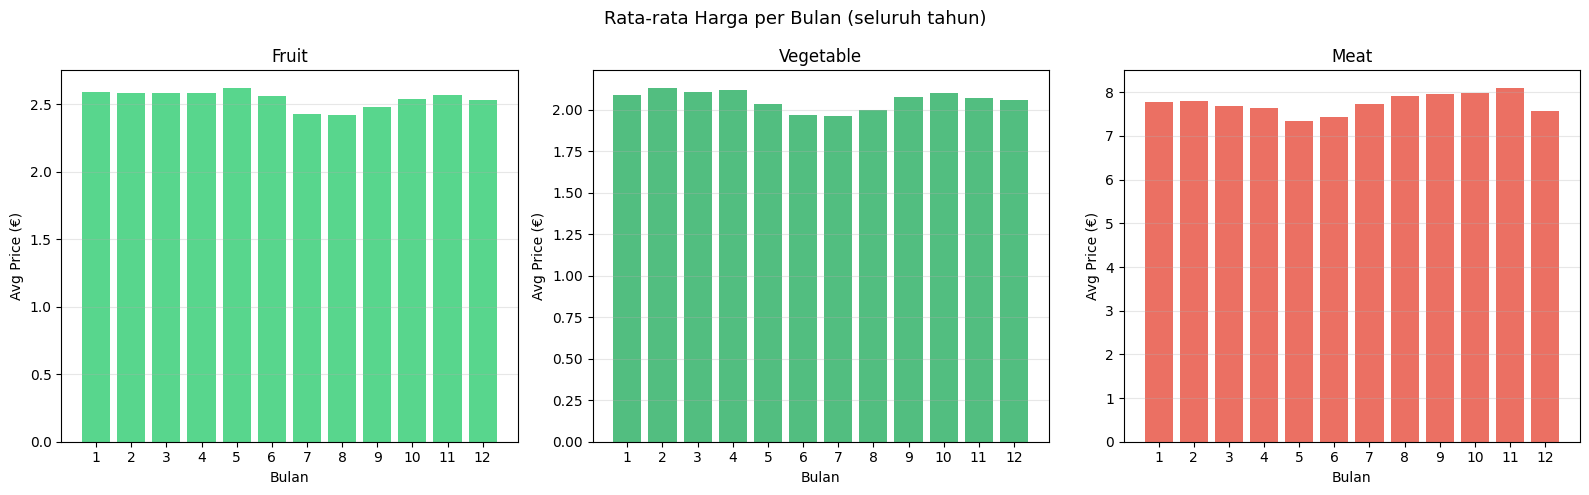

In [113]:
# Analisis pola bulanan per kategori
df_daily['month'] = df_daily['day'].dt.month

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, cat, color in zip(axes, CATEGORIES, COLORS):
    data = df_daily[df_daily['COICOP4'] == cat]
    monthly_avg = data.groupby('month')['avg_price'].mean()
    ax.bar(monthly_avg.index, monthly_avg.values, color=color, alpha=0.8)
    ax.set_title(f'{cat}', fontsize=12)
    ax.set_xlabel('Bulan')
    ax.set_ylabel('Avg Price (€)')
    ax.set_xticks(range(1, 13))
    ax.grid(True, alpha=0.3, axis='y')
plt.suptitle('Rata-rata Harga per Bulan (seluruh tahun)', fontsize=13)
plt.tight_layout()
plt.show()

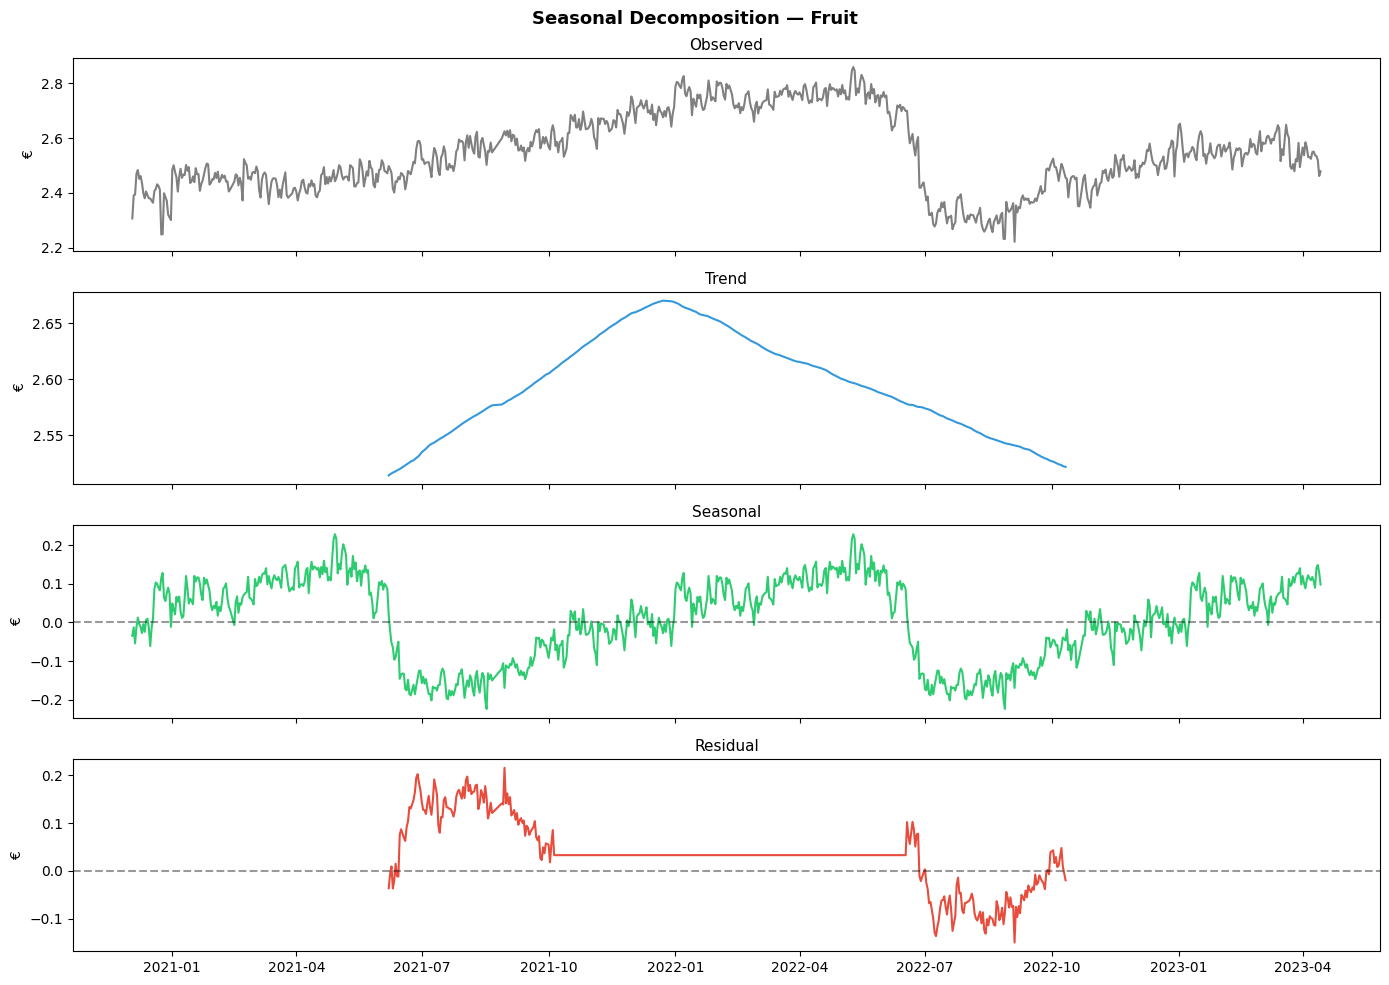

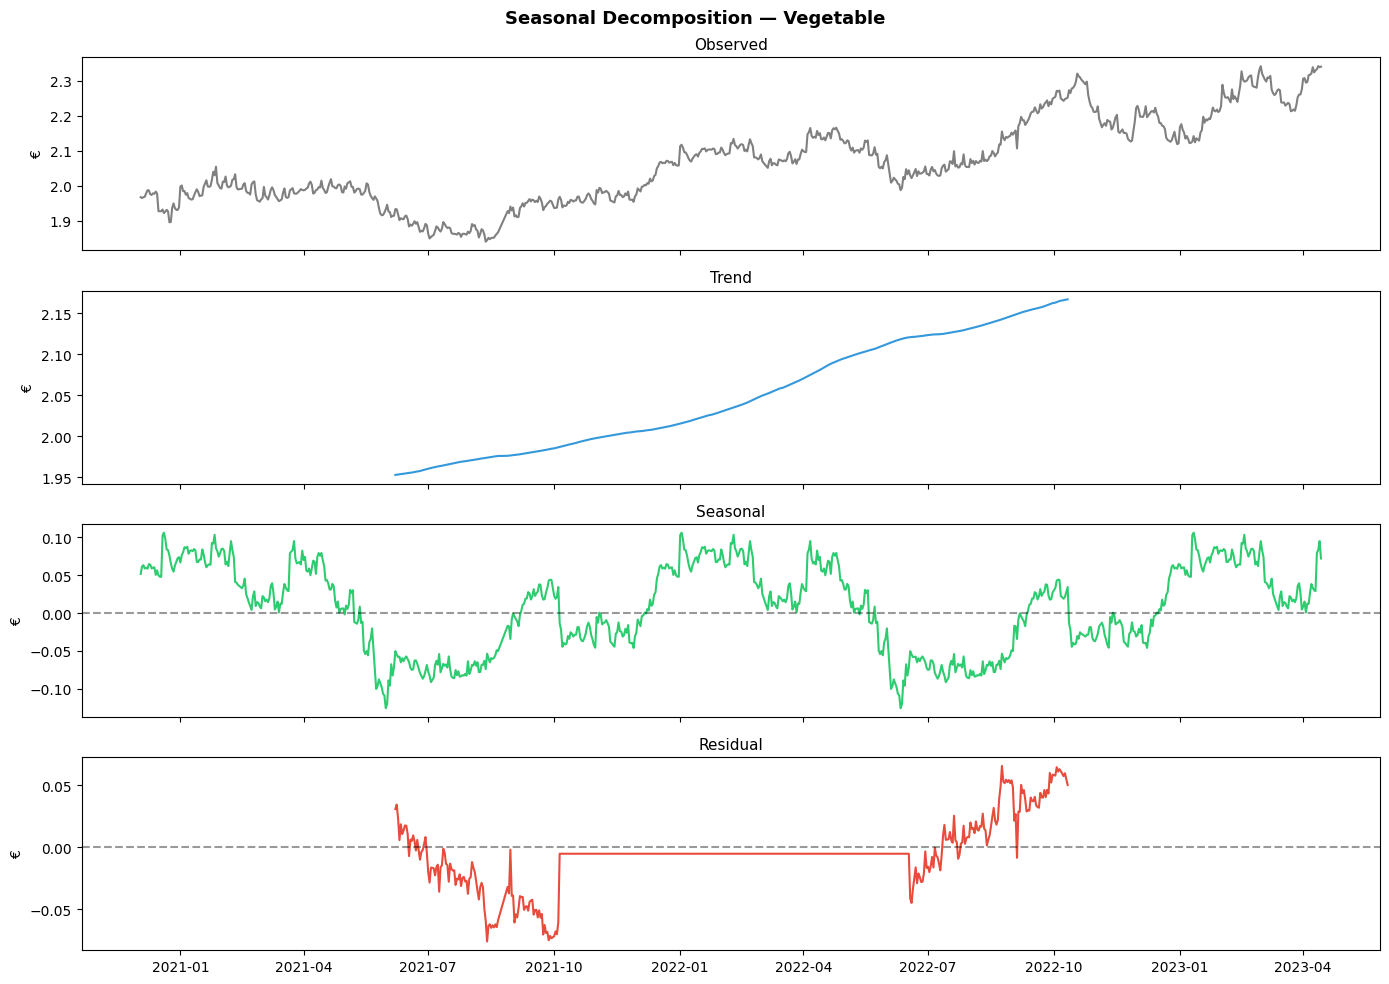

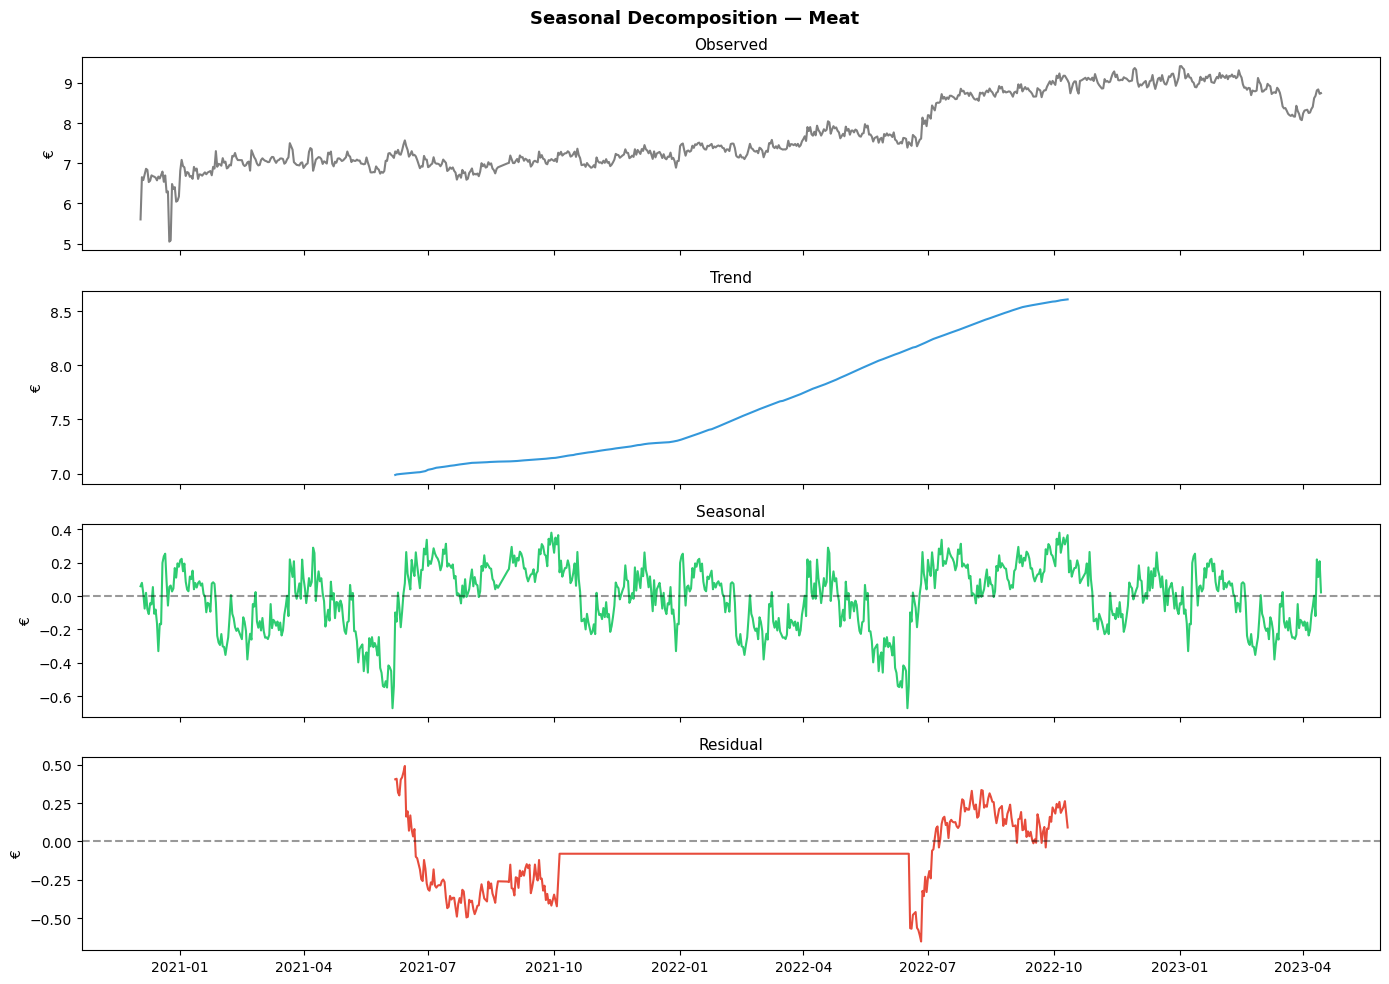

In [15]:
# Seasonal decomposition
decomp_colors = {'Trend': '#3498db', 'Seasonal': '#2ecc71', 'Residual': '#e74c3c'}
for cat in CATEGORIES:
    data = df_daily[df_daily['COICOP4'] == cat].set_index('day')['avg_price']
    decomp = seasonal_decompose(data, model='additive', period=365)

    fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
    axes[0].plot(decomp.observed, color='gray', linewidth=1.5)
    axes[0].set_title('Observed', fontsize=11)
    axes[0].set_ylabel('€')
    axes[1].plot(decomp.trend, color=decomp_colors['Trend'], linewidth=1.5)
    axes[1].set_title('Trend', fontsize=11)
    axes[1].set_ylabel('€')
    axes[2].plot(decomp.seasonal, color=decomp_colors['Seasonal'], linewidth=1.5)
    axes[2].axhline(y=0, color='black', linestyle='--', alpha=0.4)
    axes[2].set_title('Seasonal', fontsize=11)
    axes[2].set_ylabel('€')
    axes[3].plot(decomp.resid, color=decomp_colors['Residual'], linewidth=1.5)
    axes[3].axhline(y=0, color='black', linestyle='--', alpha=0.4)
    axes[3].set_title('Residual', fontsize=11)
    axes[3].set_ylabel('€')
    plt.suptitle(f'Seasonal Decomposition — {cat}', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

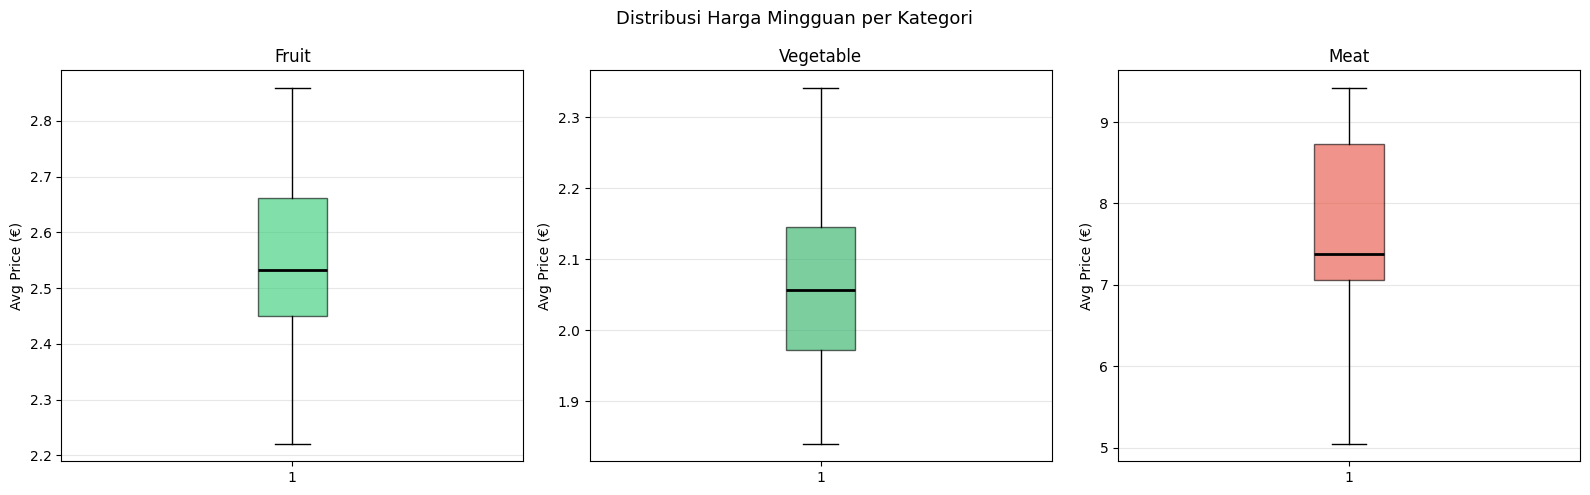

In [114]:
# Boxplot distribusi harga
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, cat, color in zip(axes, CATEGORIES, COLORS):
    data = df_daily[df_daily['COICOP4'] == cat]['avg_price']
    ax.boxplot(data, patch_artist=True,
               boxprops=dict(facecolor=color, alpha=0.6),
               medianprops=dict(color='black', linewidth=2))
    ax.set_title(f'{cat}', fontsize=12)
    ax.set_ylabel('Avg Price (€)')
    ax.grid(True, alpha=0.3, axis='y')
plt.suptitle('Distribusi Harga Mingguan per Kategori', fontsize=13)
plt.tight_layout()
plt.show()

In [17]:
# ADF Test — Stasioneritas
for cat in CATEGORIES:
    data = df_daily[df_daily['COICOP4'] == cat]['avg_price']
    result = adfuller(data)
    print(f"\n{cat}")
    print(f"  ADF Statistic : {result[0]:.4f}")
    print(f"  p-value       : {result[1]:.4f}")
    print(f"  Stasioner?    : {'Ya' if result[1] < 0.05 else 'Tidak'}")


Fruit
  ADF Statistic : -1.7860
  p-value       : 0.3874
  Stasioner?    : Tidak

Vegetable
  ADF Statistic : -0.6885
  p-value       : 0.8497
  Stasioner?    : Tidak

Meat
  ADF Statistic : -1.0525
  p-value       : 0.7336
  Stasioner?    : Tidak


### Temuan Utama

**Tren**
- Vegetable & Meat: tren naik konsisten sepanjang periode
- Fruit: naik hingga pertengahan 2022, kemudian turun
- Lonjakan harga Meat di awal 2022 mengindikasikan dampak inflasi pasca invasi Rusia–Ukraina

**Seasonality**
- Fruit & Vegetable: pola musiman kuat — harga mencapai titik terendah di bulan Juli (puncak panen musim panas Italia)
- Meat: pola musiman lebih lemah — puncak harga di sekitar Oktober (menjelang musim dingin)

**Outlier**
- Tidak ditemukan outlier 

**Stasioneritas (ADF Test)**
Ketiga kategori tidak stasioner — akan ditangani dengan differencing pada tahap preprocessing.

# **BAB 4 – Memvalidasi Data**

In [18]:
print("=== MISSING VALUES ===")
print(df.isnull().sum())

=== MISSING VALUES ===
date          0
price         0
product_id    0
store_id      0
region        0
product       0
COICOP5       0
COICOP4       0
dtype: int64


In [19]:
print("\n=== DUPLIKASI ===")
print(f"Jumlah baris duplikat: {df.duplicated().sum()}")


=== DUPLIKASI ===
Jumlah baris duplikat: 0


In [20]:
print("\n=== MISSING VALUES SETELAH AGREGASI ===")
print(df_daily.isnull().sum())


=== MISSING VALUES SETELAH AGREGASI ===
COICOP4      0
day          0
avg_price    0
month        0
dtype: int64


In [21]:
print("\n=== GAPS HARIAN ===")
for cat in CATEGORIES:
    data = df_daily[df_daily['COICOP4'] == cat].set_index('day')
    full_range = pd.date_range(start=data.index.min(),
                               end=data.index.max(),
                               freq='D')
    missing_days = full_range.difference(data.index)
    print(f"{cat}: {len(missing_days)} hari kosong")


=== GAPS HARIAN ===
Fruit: 22 hari kosong
Vegetable: 22 hari kosong
Meat: 22 hari kosong


In [22]:
print("=== CEK HARGA NEGATIF ATAU NOL ===")
for cat in CATEGORIES:
    data = df[df['COICOP4'] == cat]
    invalid = data[data['price'] <= 0]
    print(f"{cat}: {len(invalid)} baris dengan harga <= 0")

=== CEK HARGA NEGATIF ATAU NOL ===
Fruit: 0 baris dengan harga <= 0
Vegetable: 0 baris dengan harga <= 0
Meat: 0 baris dengan harga <= 0


# **BAB 5 – Menentukan Objek Data**

In [19]:
df_fruit = (df_daily[df_daily['COICOP4'] == 'Fruit']
            [['day', 'avg_price']]
            .reset_index(drop=True))

df_vegetable = (df_daily[df_daily['COICOP4'] == 'Vegetable']
                [['day', 'avg_price']]
                .reset_index(drop=True))

df_meat = (df_daily[df_daily['COICOP4'] == 'Meat']
           [['day', 'avg_price']]
           .reset_index(drop=True))

In [20]:
# Verifikasi objek data
for name, data in [('Fruit', df_fruit), ('Vegetable', df_vegetable), ('Meat', df_meat)]:
    print(f"\n=== {name} ===")
    print(f"Shape        : {data.shape}")
    print(f"Rentang waktu: {data['day'].min()} → {data['day'].max()}")
    print(f"Tipe kolom   :\n{data.dtypes}")
    print(data.head(3))


=== Fruit ===
Shape        : (841, 2)
Rentang waktu: 2020-12-03 00:00:00 → 2023-04-14 00:00:00
Tipe kolom   :
day          datetime64[ns]
avg_price           float64
dtype: object
         day  avg_price
0 2020-12-03   2.306573
1 2020-12-04   2.390705
2 2020-12-05   2.393694

=== Vegetable ===
Shape        : (841, 2)
Rentang waktu: 2020-12-03 00:00:00 → 2023-04-14 00:00:00
Tipe kolom   :
day          datetime64[ns]
avg_price           float64
dtype: object
         day  avg_price
0 2020-12-03   1.967376
1 2020-12-04   1.964969
2 2020-12-05   1.967321

=== Meat ===
Shape        : (841, 2)
Rentang waktu: 2020-12-03 00:00:00 → 2023-04-14 00:00:00
Tipe kolom   :
day          datetime64[ns]
avg_price           float64
dtype: object
         day  avg_price
0 2020-12-03   5.602763
1 2020-12-04   6.655147
2 2020-12-05   6.581843


# **BAB 6 – Membersihkan Data**

In [21]:
for name, data in [('Fruit', df_fruit), ('Vegetable', df_vegetable), ('Meat', df_meat)]:
    print(f"\n=== {name} ===")
    print(f"Missing values : {data.isnull().sum().sum()}")
    print(f"Duplikasi      : {data.duplicated().sum()}")
    Q1 = data['avg_price'].quantile(0.25)
    Q3 = data['avg_price'].quantile(0.75)
    IQR = Q3 - Q1
    outliers = data[(data['avg_price'] < Q1 - 1.5 * IQR) |
                    (data['avg_price'] > Q3 + 1.5 * IQR)]
    print(f"Outlier minggu : {len(outliers)}")

print("\nObjek data bersih — siap dilanjutkan ke preprocessing.")


=== Fruit ===
Missing values : 0
Duplikasi      : 0
Outlier minggu : 0

=== Vegetable ===
Missing values : 0
Duplikasi      : 0
Outlier minggu : 0

=== Meat ===
Missing values : 0
Duplikasi      : 0
Outlier minggu : 0

Objek data bersih — siap dilanjutkan ke preprocessing.


# **BAB 7 – Mengkonstruksi Data**

In [22]:
# Train/test split
train_fruit, test_fruit = split_train_test(df_fruit)
train_vegetable, test_vegetable = split_train_test(df_vegetable)
train_meat, test_meat = split_train_test(df_meat)

In [23]:
# Verifikasi split
for name, train, test in [('Fruit', train_fruit, test_fruit),
                           ('Vegetable', train_vegetable, test_vegetable),
                           ('Meat', train_meat, test_meat)]:
    print(f"\n=== {name} ===")
    print(f"Train: {len(train)} minggu | {train['day'].min().date()} → {train['day'].max().date()}")
    print(f"Test : {len(test)} minggu  | {test['day'].min().date()} → {test['day'].max().date()}")


=== Fruit ===
Train: 659 minggu | 2020-12-03 → 2022-10-11
Test : 182 minggu  | 2022-10-12 → 2023-04-14

=== Vegetable ===
Train: 659 minggu | 2020-12-03 → 2022-10-11
Test : 182 minggu  | 2022-10-12 → 2023-04-14

=== Meat ===
Train: 659 minggu | 2020-12-03 → 2022-10-11
Test : 182 minggu  | 2022-10-12 → 2023-04-14


In [24]:
# Scaling
train_fruit_sc, test_fruit_sc, scaler_fruit = scale_data(train_fruit, test_fruit)
train_vegetable_sc, test_vegetable_sc, scaler_veg = scale_data(train_vegetable, test_vegetable)
train_meat_sc, test_meat_sc, scaler_meat = scale_data(train_meat, test_meat)

In [47]:
for name, train in [('Fruit', train_fruit_sc),
                    ('Vegetable', train_vegetable_sc),
                    ('Meat', train_meat_sc)]:
    print(f"{name} — min: {train['avg_price'].min():.4f} | max: {train['avg_price'].max():.4f}")

Fruit — min: 0.0000 | max: 1.0000
Vegetable — min: 0.0000 | max: 1.0000
Meat — min: 0.0000 | max: 1.0000


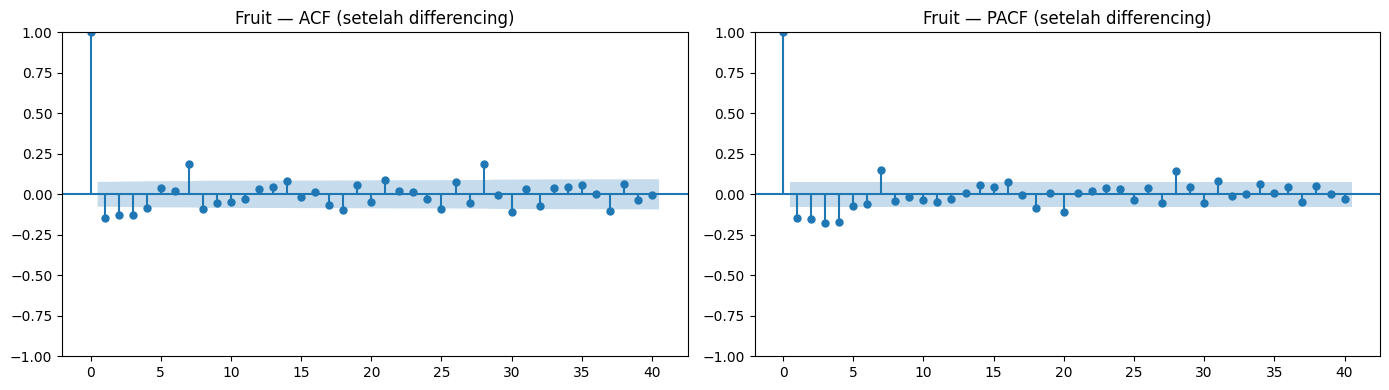

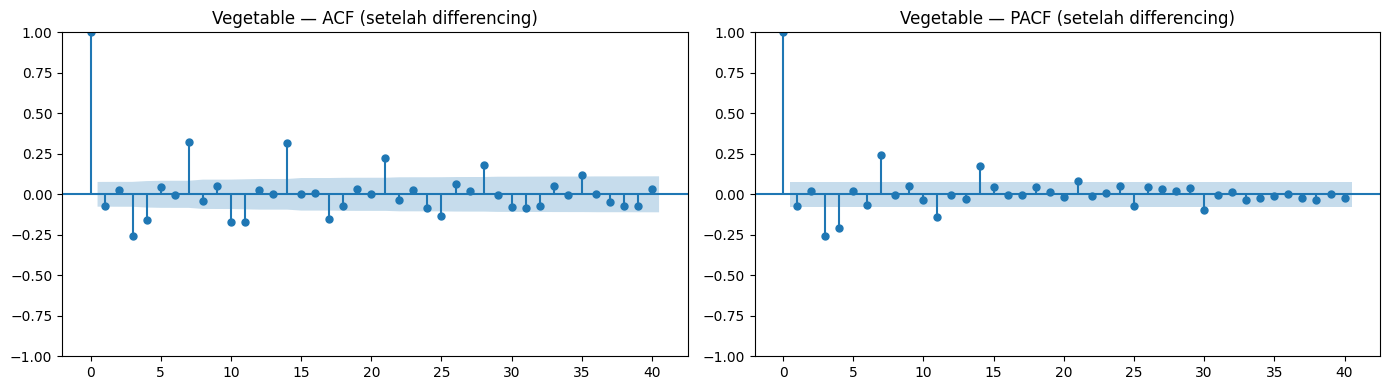

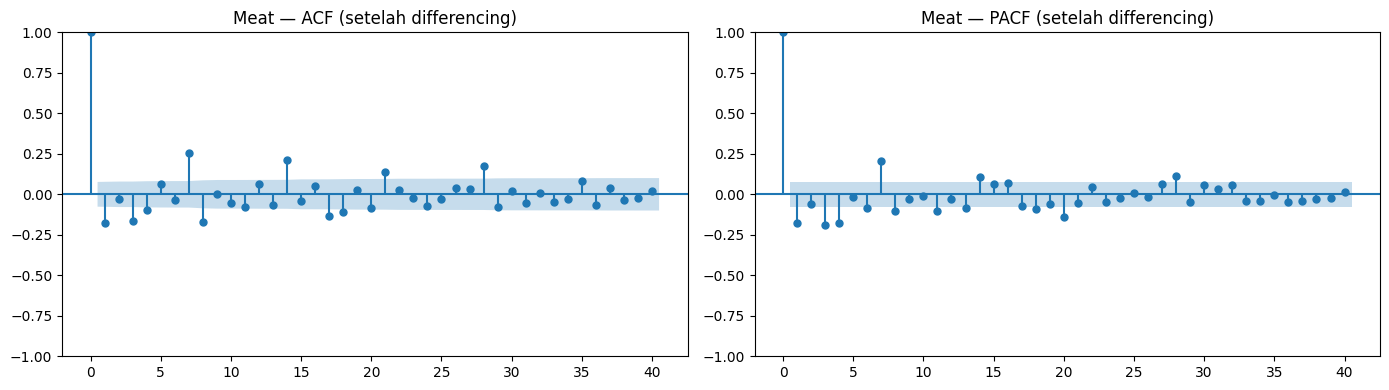

In [48]:
# ACF/PACF setelah differencing
for name, data in [('Fruit', train_fruit),
                   ('Vegetable', train_vegetable),
                   ('Meat', train_meat)]:
    diff = data['avg_price'].diff().dropna()
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    plot_acf(diff, lags=40, ax=axes[0], title=f'{name} — ACF (setelah differencing)')
    plot_pacf(diff, lags=40, ax=axes[1], title=f'{name} — PACF (setelah differencing)')
    plt.tight_layout()
    plt.show()

In [25]:
# Feature engineering
train_fruit_fe, test_fruit_fe = create_features_train_test(train_fruit_sc, test_fruit_sc)
train_vegetable_fe, test_vegetable_fe = create_features_train_test(train_vegetable_sc, test_vegetable_sc)
train_meat_fe, test_meat_fe = create_features_train_test(train_meat_sc, test_meat_sc)

print("Shape final:")
for name, train, test in [('Fruit', train_fruit_fe, test_fruit_fe),
                           ('Vegetable', train_vegetable_fe, test_vegetable_fe),
                           ('Meat', train_meat_fe, test_meat_fe)]:
    print(f"  {name} — Train: {train.shape} | Test: {test.shape}")

Shape final:
  Fruit — Train: (652, 15) | Test: (182, 15)
  Vegetable — Train: (652, 15) | Test: (182, 15)
  Meat — Train: (652, 15) | Test: (182, 15)


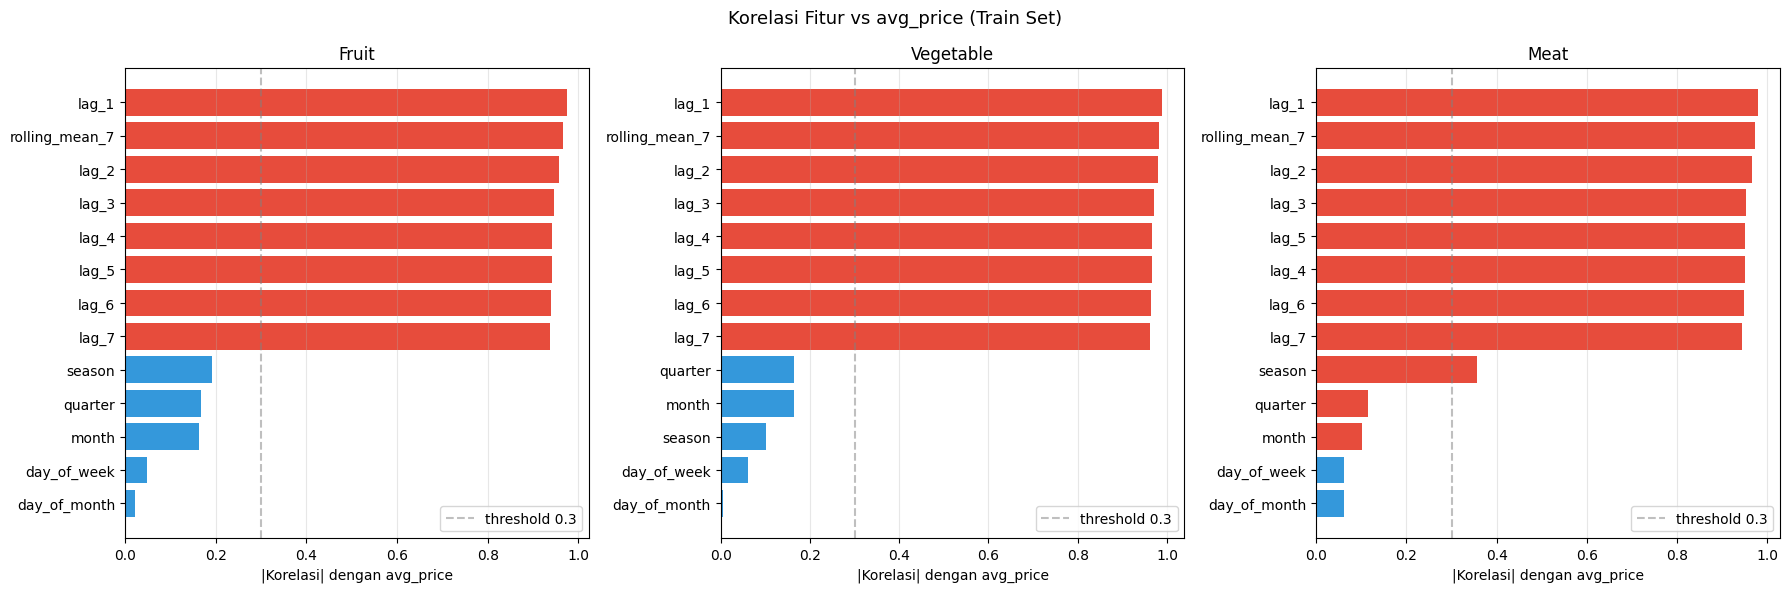

In [74]:
# Korelasi fitur vs avg_price per kategori
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (name, train_fe), color in zip(axes,
    [('Fruit', train_fruit_fe),
     ('Vegetable', train_vegetable_fe),
     ('Meat', train_meat_fe)], COLORS):

    corr = train_fe[FEATURES + ['avg_price']].corr()['avg_price'].drop('avg_price')
    corr_sorted = corr.abs().sort_values(ascending=True)

    # pakai nilai asli (dengan tanda) untuk warna
    colors_bar = ['#e74c3c' if corr[i] >= 0 else '#3498db' for i in corr_sorted.index]

    ax.barh(corr_sorted.index, corr_sorted.values, color=colors_bar)
    ax.set_title(f'{name}', fontsize=12)
    ax.set_xlabel('|Korelasi| dengan avg_price')
    ax.axvline(x=0.3, color='gray', linestyle='--', alpha=0.5, label='threshold 0.3')
    ax.legend()
    ax.grid(True, alpha=0.3, axis='x')

plt.suptitle('Korelasi Fitur vs avg_price (Train Set)', fontsize=13)
plt.tight_layout()
plt.show()

# **BAB 8 – Membangun Skenario Model**

**Tujuan:** Menentukan rencana eksperimen modeling secara menyeluruh sebelum
implementasi.

### Daftar Model yang Digunakan
Total 15 model (5 algoritma × 3 kategori) + 3 baseline naive forecast.

| Kategori | Model |
|---|---|
| Baseline | Naive Forecast |
| Statistical | ARIMA, SARIMA |
| Linear | Linear Regression |
| Tree-based | Decision Tree, XGBoost |

### Strategi Forecasting
Model ML menggunakan **recursive forecasting** — prediksi hari ke-N 
digunakan sebagai input lag untuk memprediksi hari ke-(N+1). Akibatnya error dapat terakumulasi semakin jauh horizon prediksi.

### Cara Perbandingan Model
Semua model dievaluasi pada test set yang sama menggunakan metrik yang sama.
Pemenang ditentukan berdasarkan **rata-rata MAPE terendah** di ketiga kategori.

# **BAB 9 – Membangun Model**

In [28]:
results = {}


Naive — Fruit
  MAE  : 0.0786
  RMSE : 0.0917
  MAPE : 3.08%


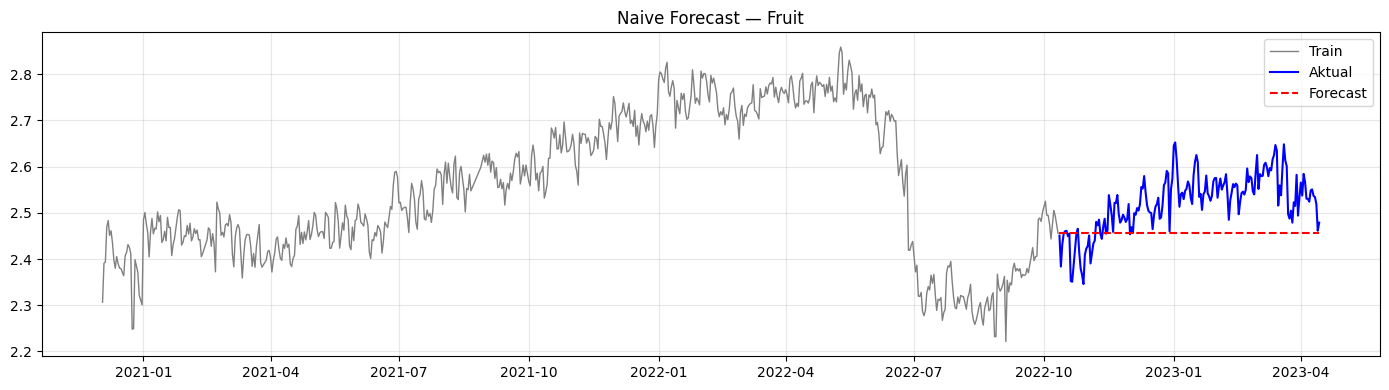


Naive — Vegetable
  MAE  : 0.0583
  RMSE : 0.0683
  MAPE : 2.65%


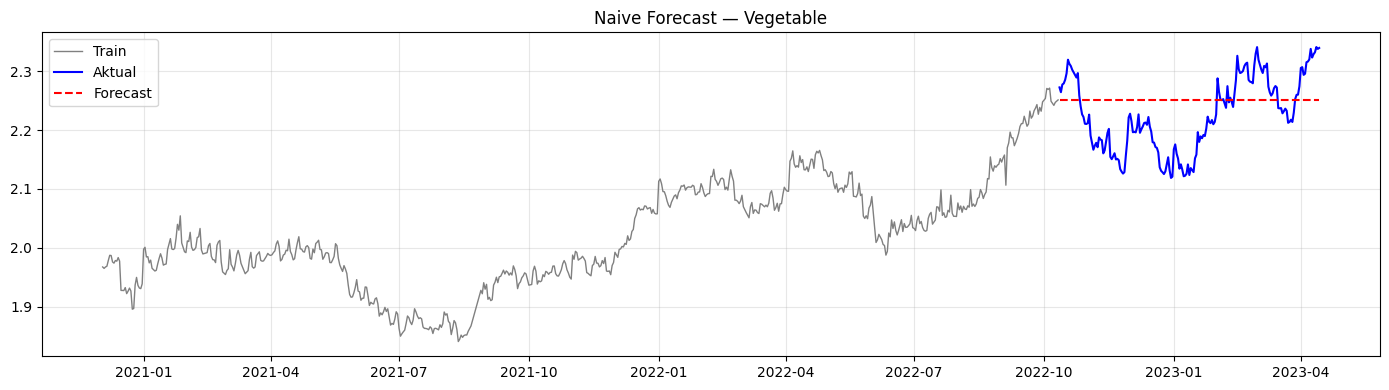


Naive — Meat
  MAE  : 0.2133
  RMSE : 0.3242
  MAPE : 2.47%


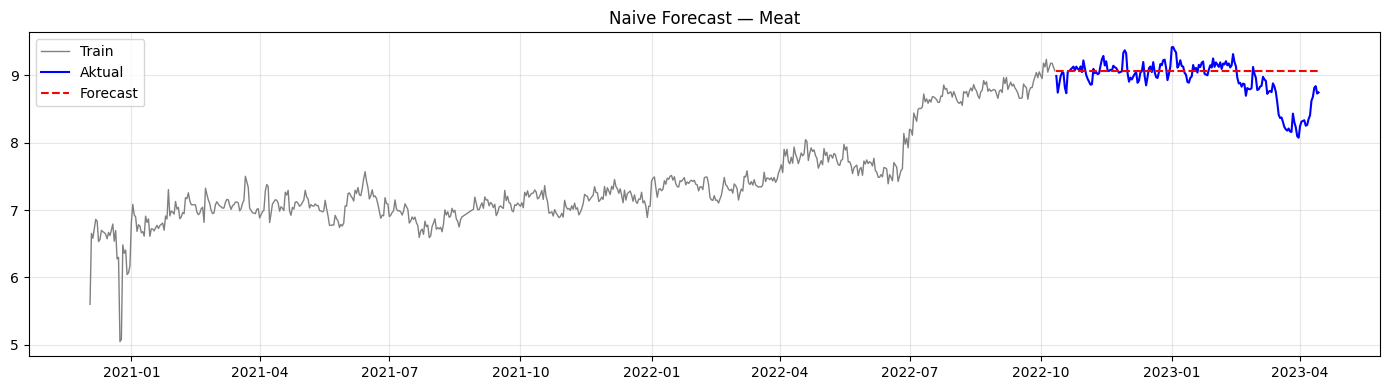

In [76]:
# --- Naive Forecast ---
for name, train, test, train_sc, test_sc, scaler in [
    ('Fruit',     train_fruit,     test_fruit,     train_fruit_sc,     test_fruit_sc,     scaler_fruit),
    ('Vegetable', train_vegetable, test_vegetable, train_vegetable_sc, test_vegetable_sc, scaler_veg),
    ('Meat',      train_meat,      test_meat,      train_meat_sc,      test_meat_sc,      scaler_meat)
]:
    naive_pred_scaled = np.full(len(test_sc), train_sc['avg_price'].iloc[-1])
    naive_pred = scaler.inverse_transform(
        naive_pred_scaled.reshape(-1, 1)).flatten()
    actual = test['avg_price'].values

    print(f"\n{'='*30}")
    results[f'Naive_{name}'] = evaluate(actual, naive_pred, label=f'Naive — {name}')
    plot_forecast(train, test, naive_pred, title=f'Naive Forecast — {name}')


Fitting ARIMA — Fruit...
  Order terpilih: (2, 1, 3)

ARIMA — Fruit
  MAE  : 0.0730
  RMSE : 0.0858
  MAPE : 2.86%


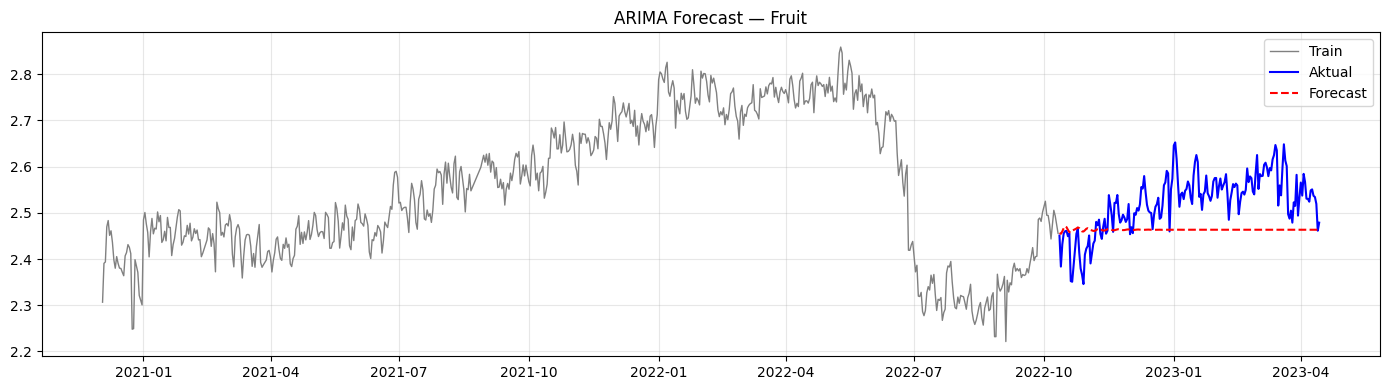


Fitting ARIMA — Vegetable...
  Order terpilih: (0, 1, 3)

ARIMA — Vegetable
  MAE  : 0.0724
  RMSE : 0.0866
  MAPE : 3.31%


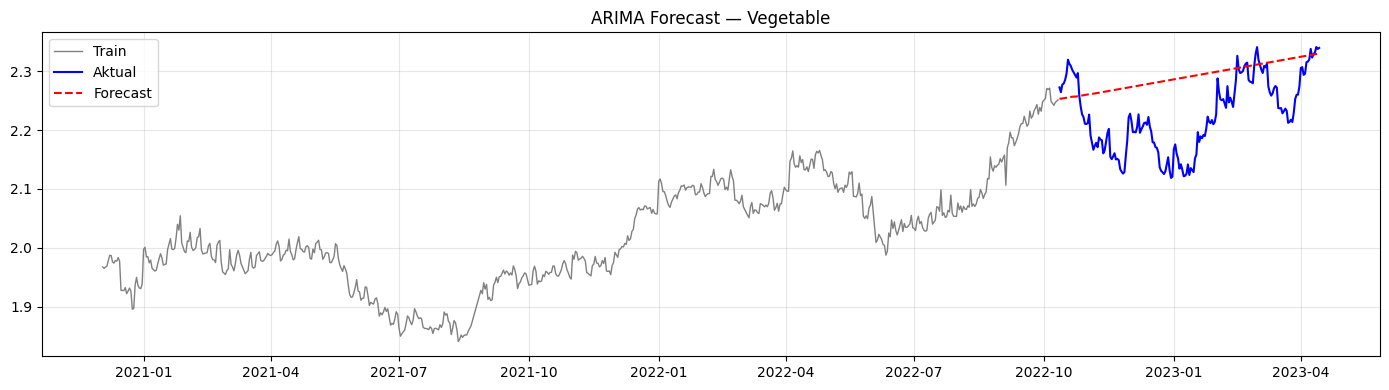


Fitting ARIMA — Meat...
  Order terpilih: (1, 1, 1)

ARIMA — Meat
  MAE  : 0.5528
  RMSE : 0.7233
  MAPE : 6.36%


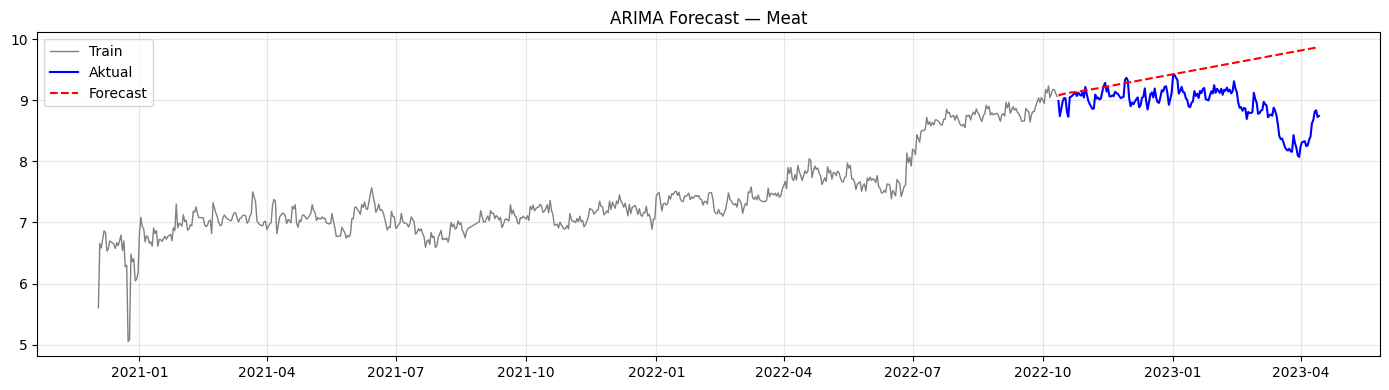

In [77]:
# --- ARIMA ---
for name, train, test in [
    ('Fruit',     train_fruit,     test_fruit),
    ('Vegetable', train_vegetable, test_vegetable),
    ('Meat',      train_meat,      test_meat)
]:
    print(f"\nFitting ARIMA — {name}...")
    model = auto_arima(
        train['avg_price'],
        seasonal=False,
        stepwise=True,
        information_criterion='aic',
        suppress_warnings=True,
        error_action='ignore'
    )
    print(f"  Order terpilih: {model.order}")

    forecast = model.predict(n_periods=len(test))
    actual = test['avg_price'].values

    print(f"\n{'='*30}")
    results[f'ARIMA_{name}'] = evaluate(actual, forecast, label=f'ARIMA — {name}')
    plot_forecast(train, test, forecast, title=f'ARIMA Forecast — {name}')


Fitting SARIMA — Fruit...
  Order terpilih: (0, 1, 3) x (1, 0, 1, 7)
SARIMA — Fruit
  MAE  : 0.0447
  RMSE : 0.0559
  MAPE : 1.76%


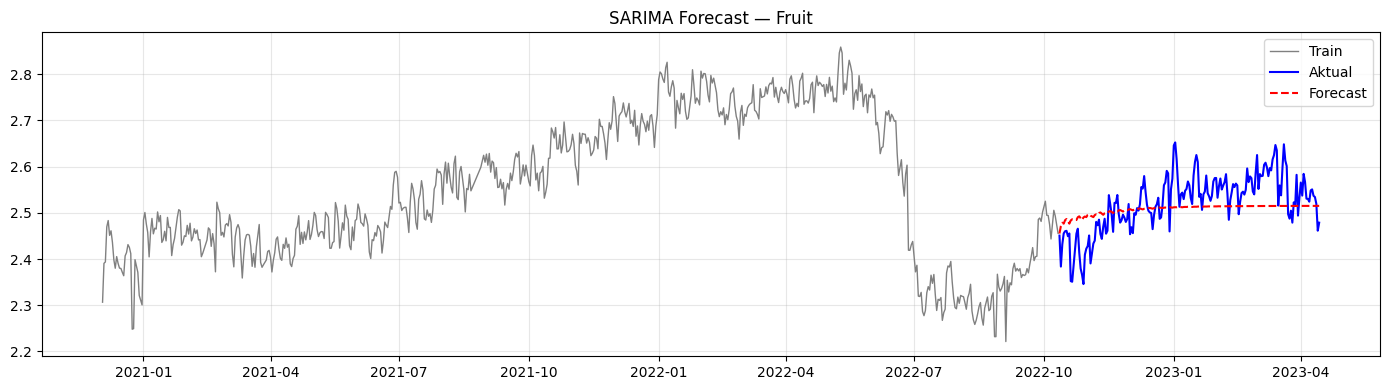


Fitting SARIMA — Vegetable...
  Order terpilih: (3, 1, 1) x (1, 0, 2, 7)
SARIMA — Vegetable
  MAE  : 0.0663
  RMSE : 0.0793
  MAPE : 3.03%


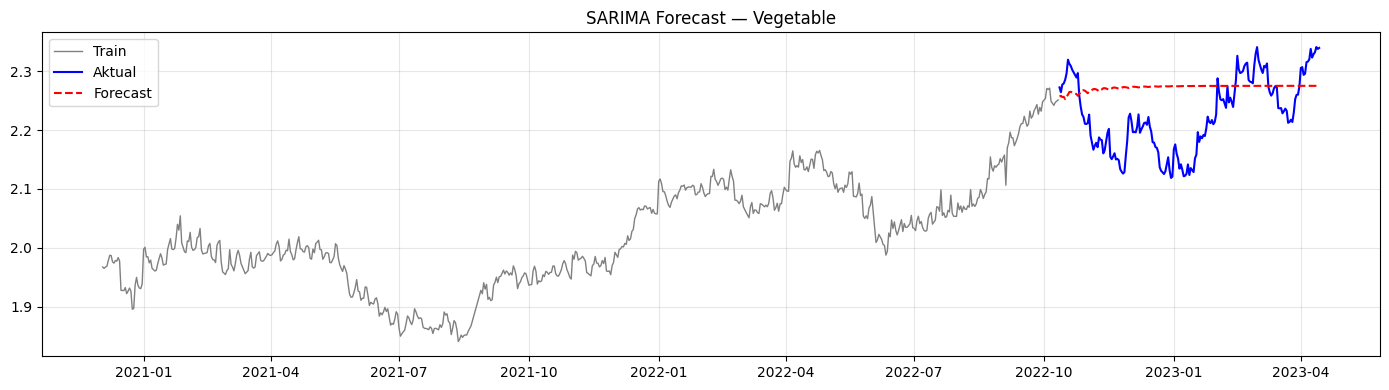


Fitting SARIMA — Meat...
  Order terpilih: (1, 1, 1) x (1, 0, 1, 7)
SARIMA — Meat
  MAE  : 0.2764
  RMSE : 0.4007
  MAPE : 3.21%


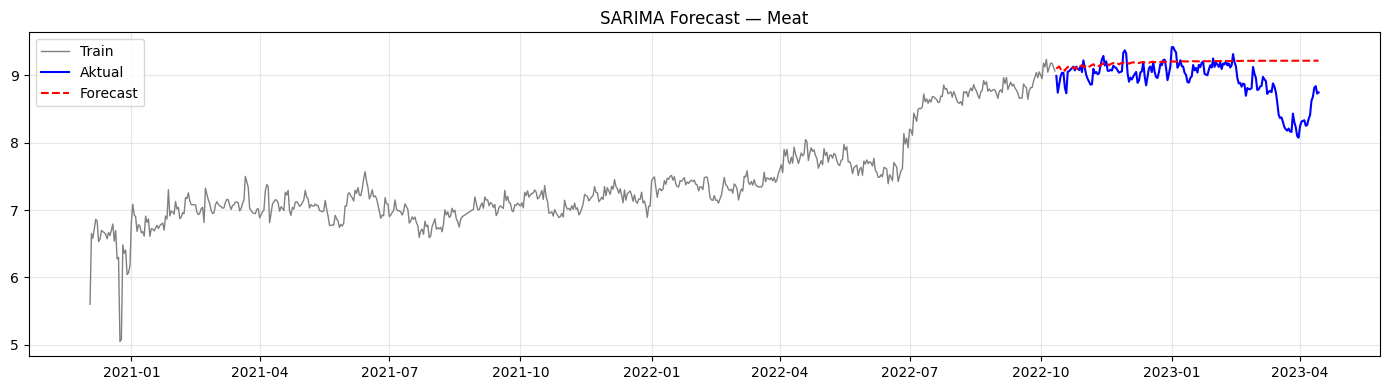

In [91]:
# --- SARIMA ---
for name, train, test in [
    ('Fruit',     train_fruit,     test_fruit),
    ('Vegetable', train_vegetable, test_vegetable),
    ('Meat',      train_meat,      test_meat)
]:
    print(f"\nFitting SARIMA — {name}...")
    model = auto_arima(
        train['avg_price'],
        seasonal=True,
        m=7,
        stepwise=True,
        information_criterion='aic',
        suppress_warnings=True,
        error_action='ignore',
        max_p=3, max_q=3,
        max_P=2, max_Q=2
    )
    print(f"  Order terpilih: {model.order} x {model.seasonal_order}")

    forecast = model.predict(n_periods=len(test))
    actual = test['avg_price'].values

    results[f'SARIMA_{name}'] = evaluate(actual, forecast, label=f'SARIMA — {name}')
    plot_forecast(train, test, forecast, title=f'SARIMA Forecast — {name}')

Linear Regression — Fruit
  MAE  : 0.0674
  RMSE : 0.0805
  MAPE : 2.65%


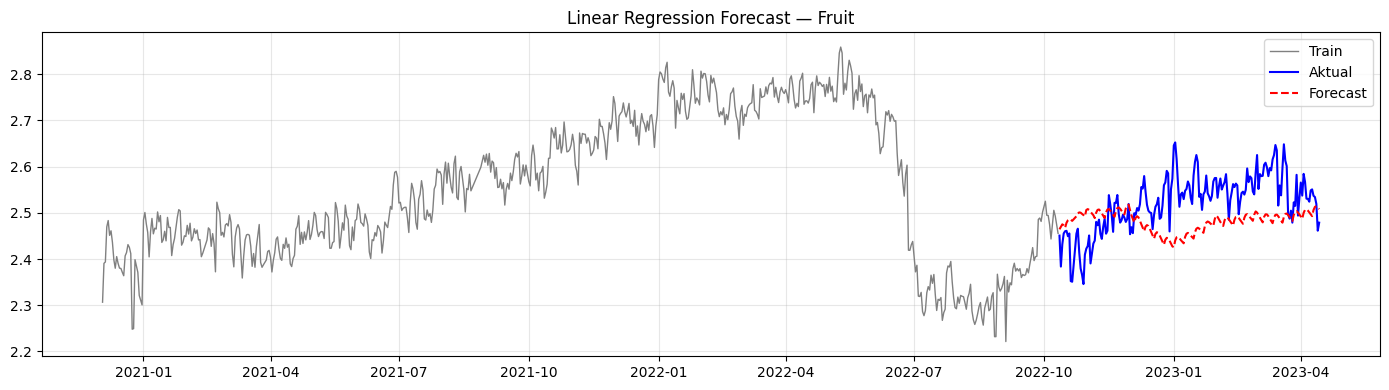

Linear Regression — Vegetable
  MAE  : 0.1579
  RMSE : 0.1690
  MAPE : 7.15%


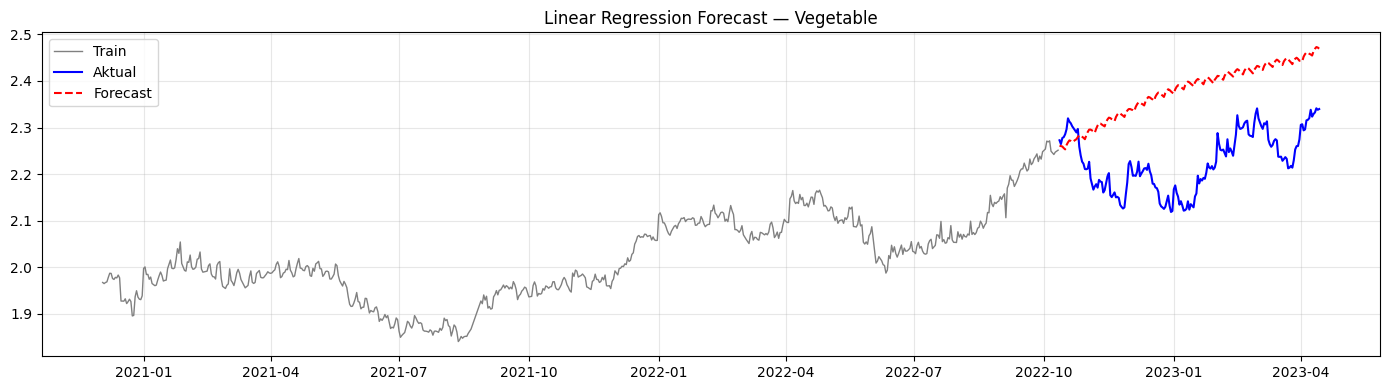

Linear Regression — Meat
  MAE  : 0.2651
  RMSE : 0.3411
  MAPE : 3.03%


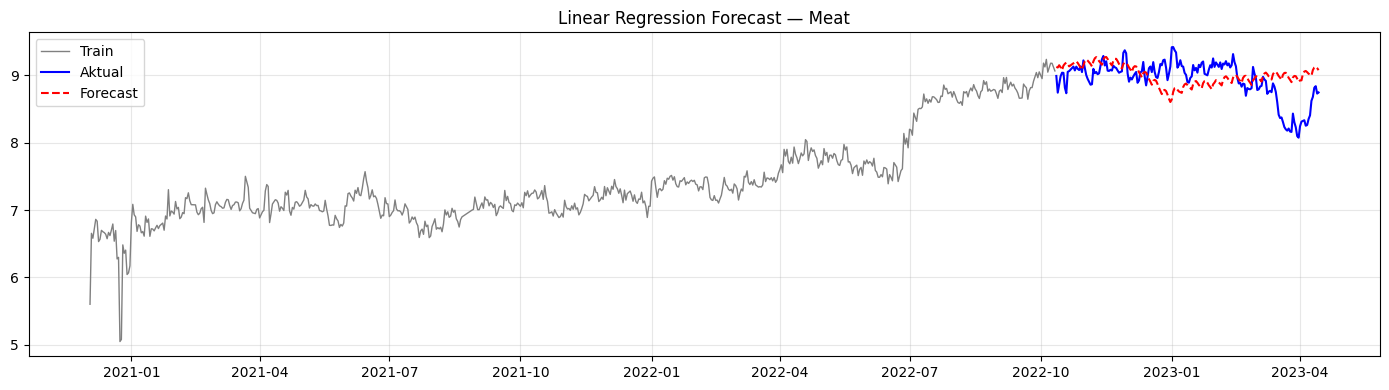

In [78]:
# --- Linear Regression ---
for name, train_fe, test_fe, train, test, scaler in [
    ('Fruit',     train_fruit_fe,     test_fruit_fe,     train_fruit,     test_fruit,     scaler_fruit),
    ('Vegetable', train_vegetable_fe, test_vegetable_fe, train_vegetable, test_vegetable, scaler_veg),
    ('Meat',      train_meat_fe,      test_meat_fe,      train_meat,      test_meat,      scaler_meat)
]:
    model = LinearRegression()
    model.fit(train_fe[FEATURES], train_fe['avg_price'])
    forecast = recursive_forecast(model, test_fe, train_fe, scaler)
    actual = test['avg_price'].values
    results[f'LR_{name}'] = evaluate(actual, forecast, label=f'Linear Regression — {name}')
    plot_forecast(train, test, forecast, title=f'Linear Regression Forecast — {name}')

Decision Tree — Fruit
  MAE  : 0.0996
  RMSE : 0.1123
  MAPE : 3.99%


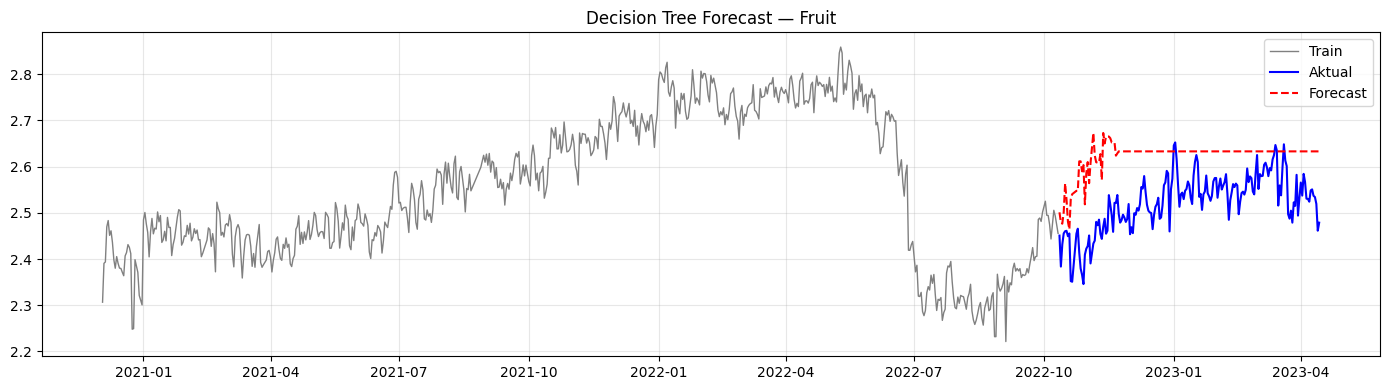

Decision Tree — Vegetable
  MAE  : 0.0581
  RMSE : 0.0682
  MAPE : 2.64%


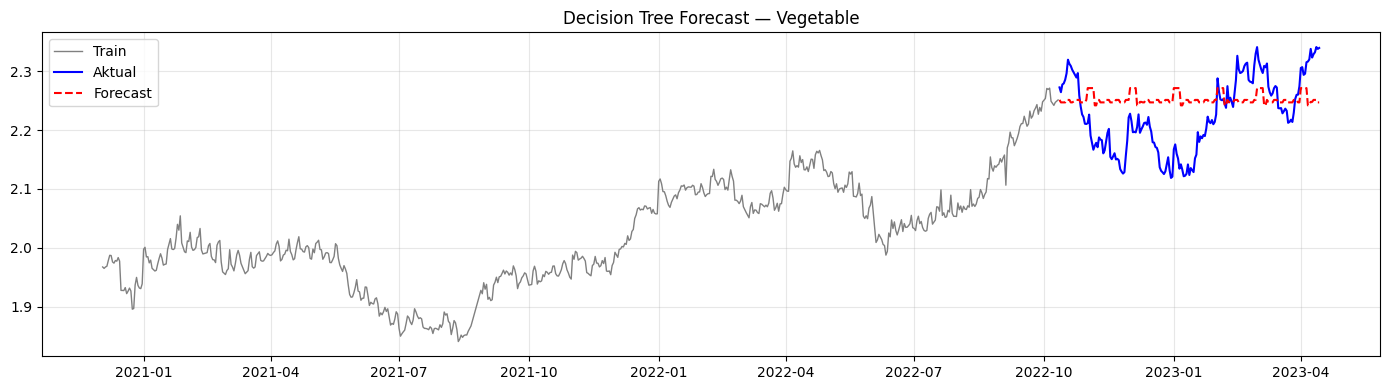

Decision Tree — Meat
  MAE  : 0.2299
  RMSE : 0.3451
  MAPE : 2.67%


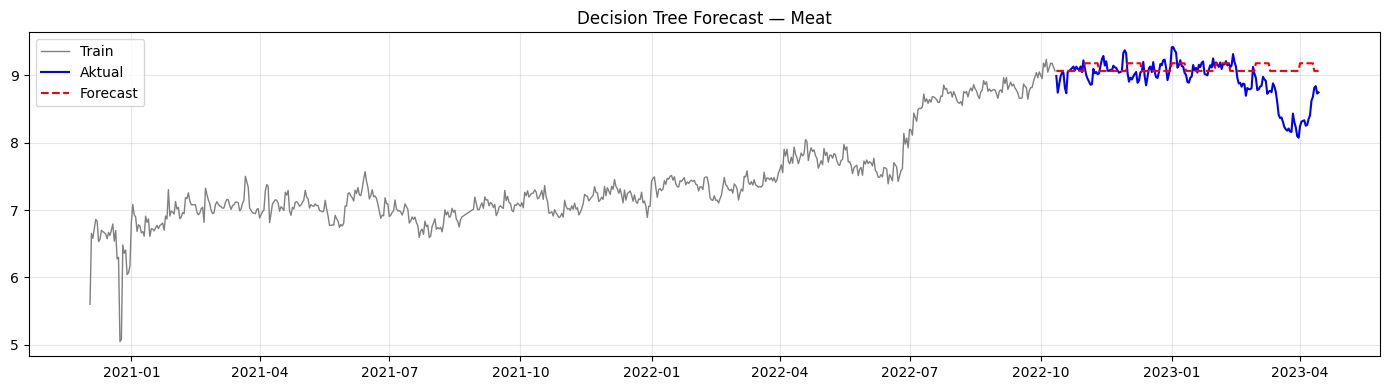

In [79]:
# --- Decision Tree ---
for name, train_fe, test_fe, train, test, scaler in [
    ('Fruit',     train_fruit_fe,     test_fruit_fe,     train_fruit,     test_fruit,     scaler_fruit),
    ('Vegetable', train_vegetable_fe, test_vegetable_fe, train_vegetable, test_vegetable, scaler_veg),
    ('Meat',      train_meat_fe,      test_meat_fe,      train_meat,      test_meat,      scaler_meat)
]:
    model = DecisionTreeRegressor(random_state=42)
    model.fit(train_fe[FEATURES], train_fe['avg_price'])
    forecast = recursive_forecast(model, test_fe, train_fe, scaler)
    actual = test['avg_price'].values
    results[f'DT_{name}'] = evaluate(actual, forecast, label=f'Decision Tree — {name}')
    plot_forecast(train, test, forecast, title=f'Decision Tree Forecast — {name}')

XGBoost — Fruit
  MAE  : 0.1109
  RMSE : 0.1285
  MAPE : 4.35%


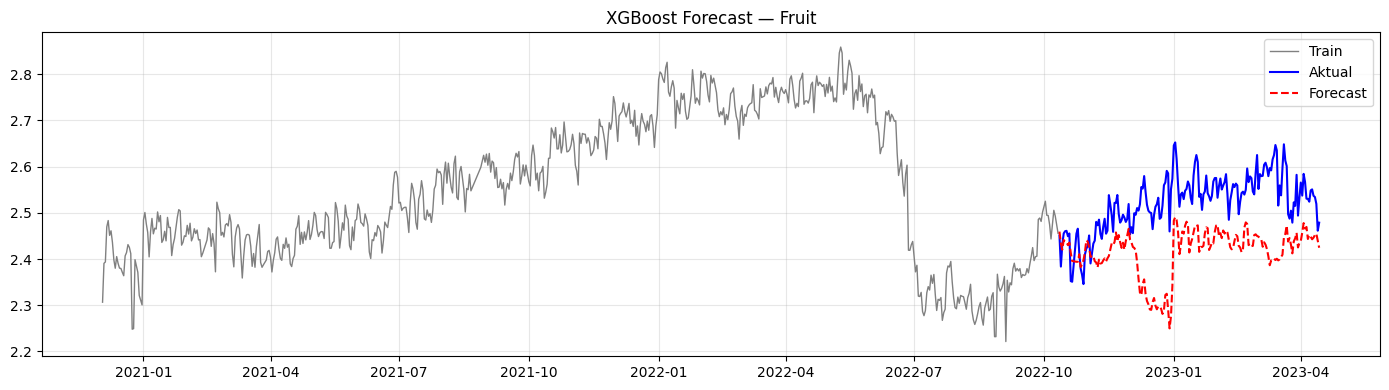

XGBoost — Vegetable
  MAE  : 0.0980
  RMSE : 0.1148
  MAPE : 4.36%


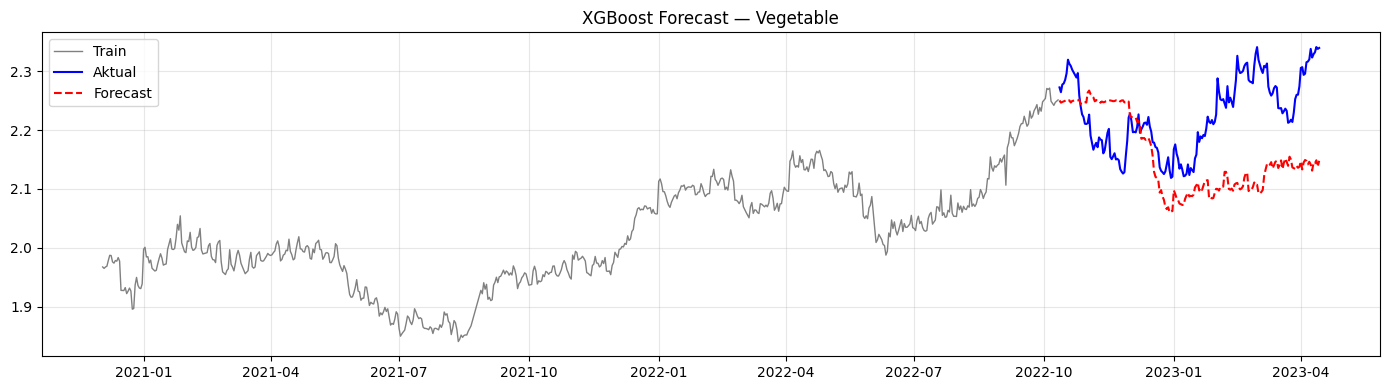

XGBoost — Meat
  MAE  : 0.2391
  RMSE : 0.3547
  MAPE : 2.77%


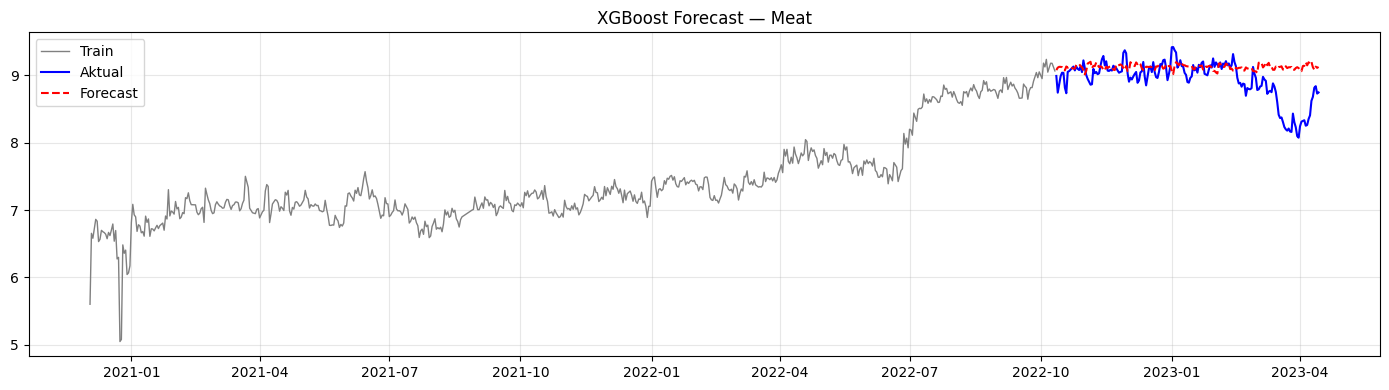

In [80]:
# --- XGBoost ---
for name, train_fe, test_fe, train, test, scaler in [
    ('Fruit',     train_fruit_fe,     test_fruit_fe,     train_fruit,     test_fruit,     scaler_fruit),
    ('Vegetable', train_vegetable_fe, test_vegetable_fe, train_vegetable, test_vegetable, scaler_veg),
    ('Meat',      train_meat_fe,      test_meat_fe,      train_meat,      test_meat,      scaler_meat)
]:
    model = XGBRegressor(random_state=42, verbosity=0)
    model.fit(train_fe[FEATURES], train_fe['avg_price'])
    forecast = recursive_forecast(model, test_fe, train_fe, scaler)
    actual = test['avg_price'].values
    results[f'XGB_{name}'] = evaluate(actual, forecast, label=f'XGBoost — {name}')
    plot_forecast(train, test, forecast, title=f'XGBoost Forecast — {name}')


Kategori: Fruit
Ridge — Fruit
  MAE  : 0.0615
  RMSE : 0.0742
  MAPE : 2.42%


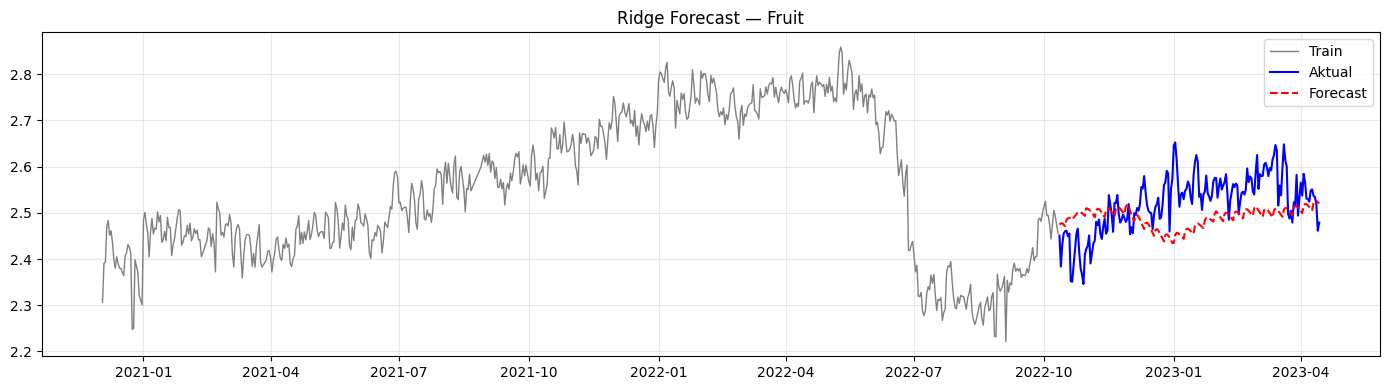


Kategori: Vegetable
Ridge — Vegetable
  MAE  : 0.1316
  RMSE : 0.1435
  MAPE : 5.98%


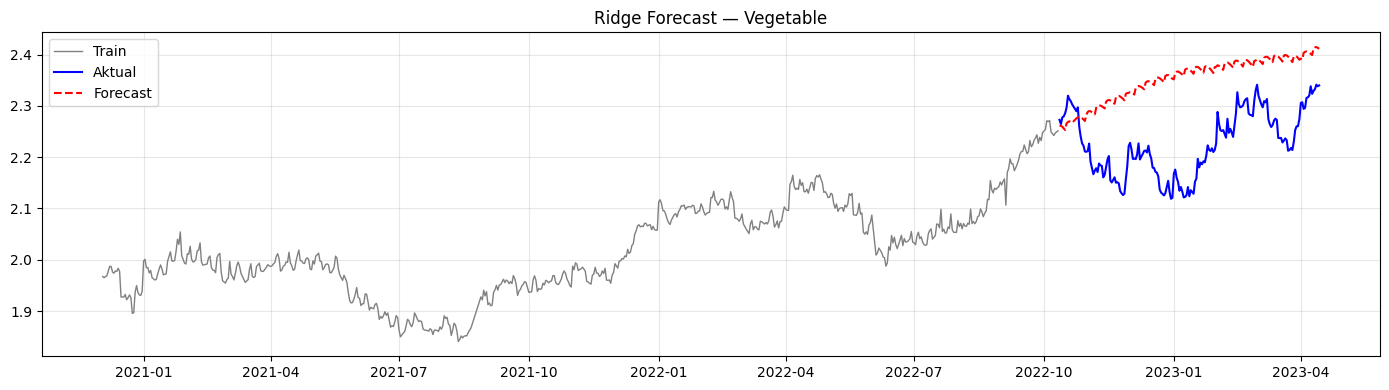


Kategori: Meat
Ridge — Meat
  MAE  : 0.3115
  RMSE : 0.3833
  MAPE : 3.47%


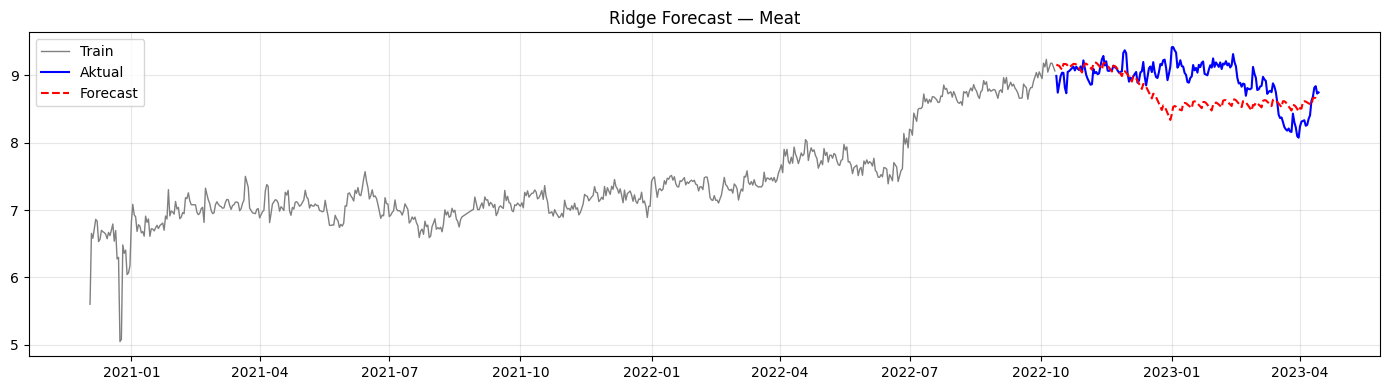

In [81]:
# --- Ridge ---
for name, train_fe, test_fe, train, test, scaler in [
    ('Fruit',     train_fruit_fe,     test_fruit_fe,     train_fruit,     test_fruit,     scaler_fruit),
    ('Vegetable', train_vegetable_fe, test_vegetable_fe, train_vegetable, test_vegetable, scaler_veg),
    ('Meat',      train_meat_fe,      test_meat_fe,      train_meat,      test_meat,      scaler_meat)
]:
    print(f"\n{'='*40}")
    print(f"Kategori: {name}")
    ridge = Ridge()
    ridge.fit(train_fe[FEATURES], train_fe['avg_price'])
    forecast_ridge = recursive_forecast(ridge, test_fe, train_fe, scaler)
    results[f'Ridge_{name}'] = evaluate(test['avg_price'].values,
                                        forecast_ridge,
                                        label=f'Ridge — {name}')
    plot_forecast(train, test, forecast_ridge, title=f'Ridge Forecast — {name}')

## Hasil Modeling

### Model yang Dibangun
Total 8 model × 3 kategori = 24 model.

| Kategori | Model |
|---|---|
| Baseline | Naive Forecast |
| Statistical | ARIMA, SARIMA |
| Linear | Linear Regression, Ridge |
| Tree-based | Decision Tree, XGBoost |

### Rekap Hasil MAPE (%)

| Model | Fruit | Vegetable | Meat |
|---|---|---|---|
| Naive | 3.08% | 2.65% | 2.47% |
| ARIMA | 2.86% | 3.31% | 6.36% |
| SARIMA | **1.76%** | 3.03% | 3.21% |
| Linear Regression | 2.65% | 7.15% | 3.03% |
| Ridge | 2.42% | 5.98% | 3.47% |
| Decision Tree | 3.99% | **2.64%** | 2.67% |
| XGBoost | 4.35% | 4.36% | 2.77% |

### Temuan Utama

- Naive Forecast sangat kompetitif — mencerminkan sifat *persistence* harga komoditas
- SARIMA unggul untuk Fruit, mengindikasikan adanya pola seasonal yang berhasil ditangkap
- ARIMA mengalami penurunan performa signifikan untuk Meat (6.36%) — pola Meat lebih kompleks
- Tidak ada satu model yang dominan di semua kategori
- Linear Regression gagal total untuk Vegetable (7.15%) — mengkonfirmasi pola non-linear
- Decision Tree berhasil menangkap pola non-linear Vegetable yang gagal ditangkap model linear

### Model Terbaik per Kategori

| Kategori | Model Terbaik | MAPE |
|---|---|---|
| Fruit | SARIMA | 1.76% |
| Vegetable | Decision Tree | 2.64% |
| Meat | Naive | 2.47% |

In [26]:
# --- Hyperparameter Tuning ---
tscv = TimeSeriesSplit(n_splits=5)

Ridge best alpha: {'alpha': 0.0001}
Ridge Tuned — Fruit
  MAE  : 0.0674
  RMSE : 0.0805
  MAPE : 2.65%


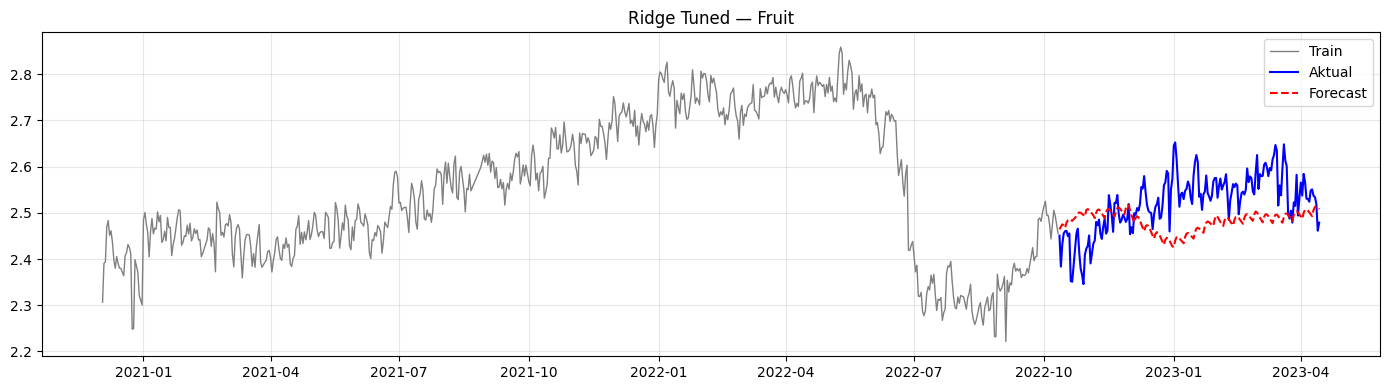

In [29]:
# Ridge tuning — Fruit
ridge_params = {'alpha': [0.0001, 0.001, 0.01, 0.1, 0.5, 1, 5, 10, 50, 100, 500, 1000]}
grid_ridge = GridSearchCV(Ridge(), ridge_params, cv=tscv,
                          scoring='neg_mean_absolute_error', n_jobs=-1)
grid_ridge.fit(train_fruit_fe[FEATURES], train_fruit_fe['avg_price'])
print(f"Ridge best alpha: {grid_ridge.best_params_}")

forecast_ridge_tuned = recursive_forecast(grid_ridge.best_estimator_,
                                          test_fruit_fe, train_fruit_fe, scaler_fruit)
results['Ridge_tuned_Fruit'] = evaluate(test_fruit['avg_price'].values,
                                        forecast_ridge_tuned,
                                        label='Ridge Tuned — Fruit')
plot_forecast(train_fruit, test_fruit, forecast_ridge_tuned,
              title='Ridge Tuned — Fruit')

XGB best params: {'colsample_bytree': 0.7, 'learning_rate': 0.2, 'max_depth': 2, 'n_estimators': 50, 'subsample': 1.0}
XGBoost Tuned — Meat
  MAE  : 0.2000
  RMSE : 0.2951
  MAPE : 2.31%


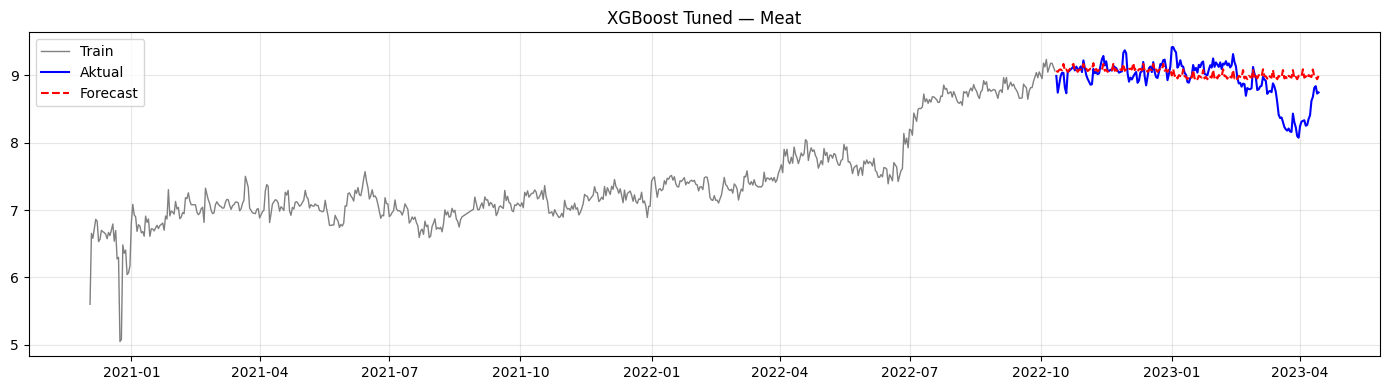

In [30]:
# XGBoost tuning — Meat
xgb_params = {
    'n_estimators': [50, 100, 200, 300, 500],
    'max_depth': [2, 3, 4, 5, 6, 7],
    'learning_rate': [0.001, 0.005, 0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}
grid_xgb = GridSearchCV(XGBRegressor(random_state=42, verbosity=0), xgb_params,
                        cv=tscv, scoring='neg_mean_absolute_error', n_jobs=-1)
grid_xgb.fit(train_meat_fe[FEATURES], train_meat_fe['avg_price'])
print(f"XGB best params: {grid_xgb.best_params_}")

forecast_xgb_tuned = recursive_forecast(grid_xgb.best_estimator_,
                                        test_meat_fe, train_meat_fe, scaler_meat)
results['XGB_tuned_Meat'] = evaluate(test_meat['avg_price'].values,
                                     forecast_xgb_tuned,
                                     label='XGBoost Tuned — Meat')
plot_forecast(train_meat, test_meat, forecast_xgb_tuned,
              title='XGBoost Tuned — Meat')

Tuning hanya memberikan improvement signifikan untuk Meat melalui XGBoost.
Model final:

| Kategori | Model Final | MAPE |
|---|---|---|
| Fruit | RIDGE | 2.42% |
| Vegetable | Decision Tree | 2.64% |
| Meat | XGBoost Tuned | 2.31% |

In [92]:
records = []
for key, val in results.items():
    parts = key.split('_')
    if len(parts) == 2:
        model_name, category = parts
    elif len(parts) == 3:
        model_name = f"{parts[0]}_{parts[1]}"
        category = parts[2]
    else:
        continue
    records.append({
        'Model': model_name,
        'Category': category,
        'MAE': round(val['MAE'], 4),
        'RMSE': round(val['RMSE'], 4),
        'MAPE': round(val['MAPE'], 2)
    })

In [93]:
df_results = pd.DataFrame(records)

In [94]:
# Tabel pivot per metrik
for metric in ['MAPE', 'MAE', 'RMSE']:
    pivot = df_results.pivot(index='Model', columns='Category', values=metric)
    print(f"\n=== {metric} ===")
    print(pivot.round(4).to_string())


=== MAPE ===
Category  Fruit  Meat  Vegetable
Model                           
ARIMA      2.86  6.36       3.31
DT         3.99  2.67       2.64
LR         2.65  3.03       7.15
Naive      3.08  2.47       2.65
Ridge      2.42  3.47       5.98
SARIMA     1.76  3.21       3.03
XGB        4.35  2.77       4.36

=== MAE ===
Category   Fruit    Meat  Vegetable
Model                              
ARIMA     0.0730  0.5528     0.0724
DT        0.0996  0.2299     0.0581
LR        0.0674  0.2651     0.1579
Naive     0.0786  0.2133     0.0583
Ridge     0.0615  0.3115     0.1316
SARIMA    0.0447  0.2764     0.0663
XGB       0.1109  0.2391     0.0980

=== RMSE ===
Category   Fruit    Meat  Vegetable
Model                              
ARIMA     0.0858  0.7233     0.0866
DT        0.1123  0.3451     0.0682
LR        0.0805  0.3411     0.1690
Naive     0.0917  0.3242     0.0683
Ridge     0.0742  0.3833     0.1435
SARIMA    0.0559  0.4007     0.0793
XGB       0.1285  0.3547     0.1148


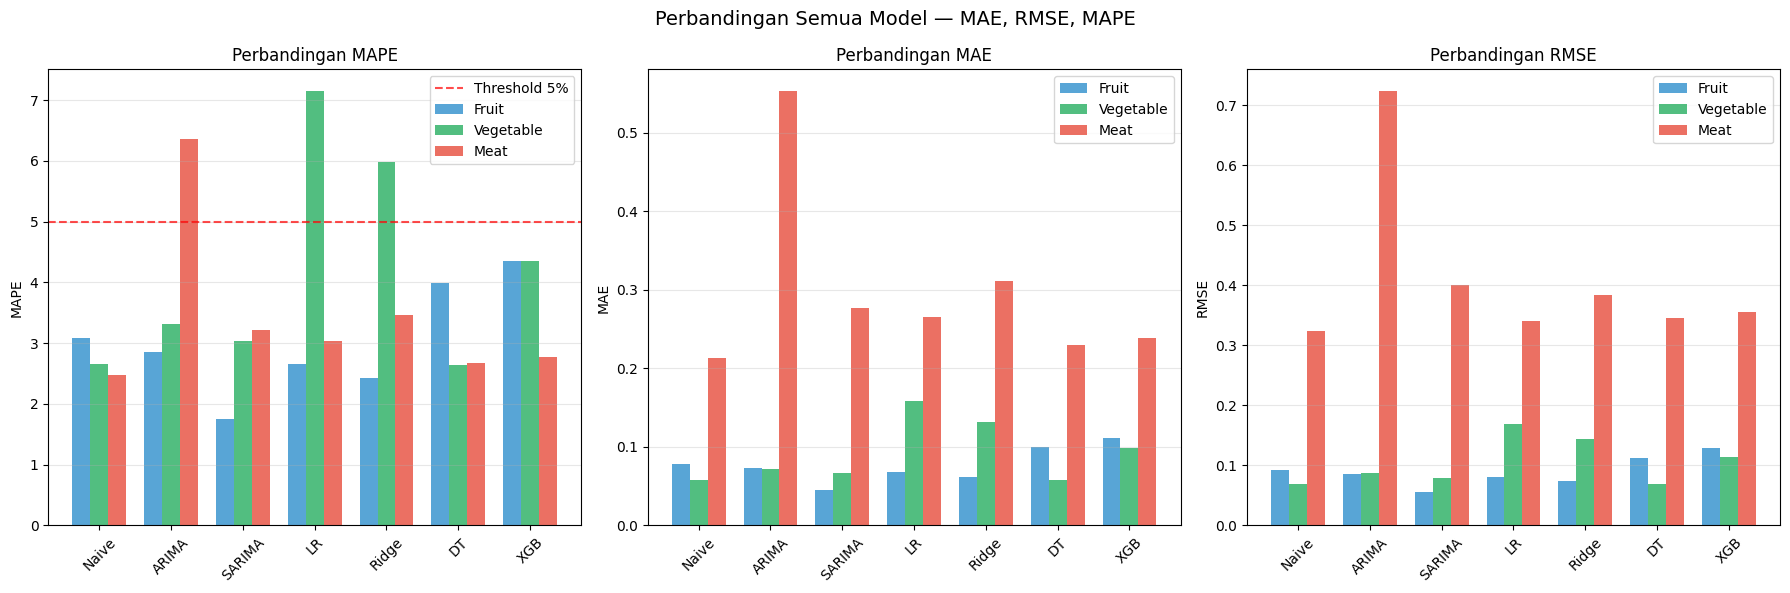

In [95]:
# Visualisasi perbandingan model
main_models = ['Naive', 'ARIMA', 'SARIMA', 'LR', 'Ridge', 'DT', 'XGB']
df_main = df_results[df_results['Model'].isin(main_models)]
metrics = ['MAPE', 'MAE', 'RMSE']
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, metric in zip(axes, metrics):
    pivot = df_main.pivot(index='Model', columns='Category', values=metric)
    pivot = pivot.reindex(main_models)
    x = np.arange(len(main_models))
    width = 0.25
    bar_colors = ["#2e8fcc", '#27ae60', '#e74c3c']

    for i, (cat, color) in enumerate(zip(CATEGORIES, bar_colors)):
        ax.bar(x + i * width, pivot[cat], width,
               label=cat, color=color, alpha=0.8)

    if metric == 'MAPE':
        ax.axhline(y=5, color='red', linestyle='--',
                   alpha=0.7, label='Threshold 5%')

    ax.set_title(f'Perbandingan {metric}', fontsize=12)
    ax.set_xticks(x + width)
    ax.set_xticklabels(main_models, rotation=45)
    ax.set_ylabel(metric)
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('Perbandingan Semua Model — MAE, RMSE, MAPE', fontsize=14)
plt.tight_layout()
plt.show()

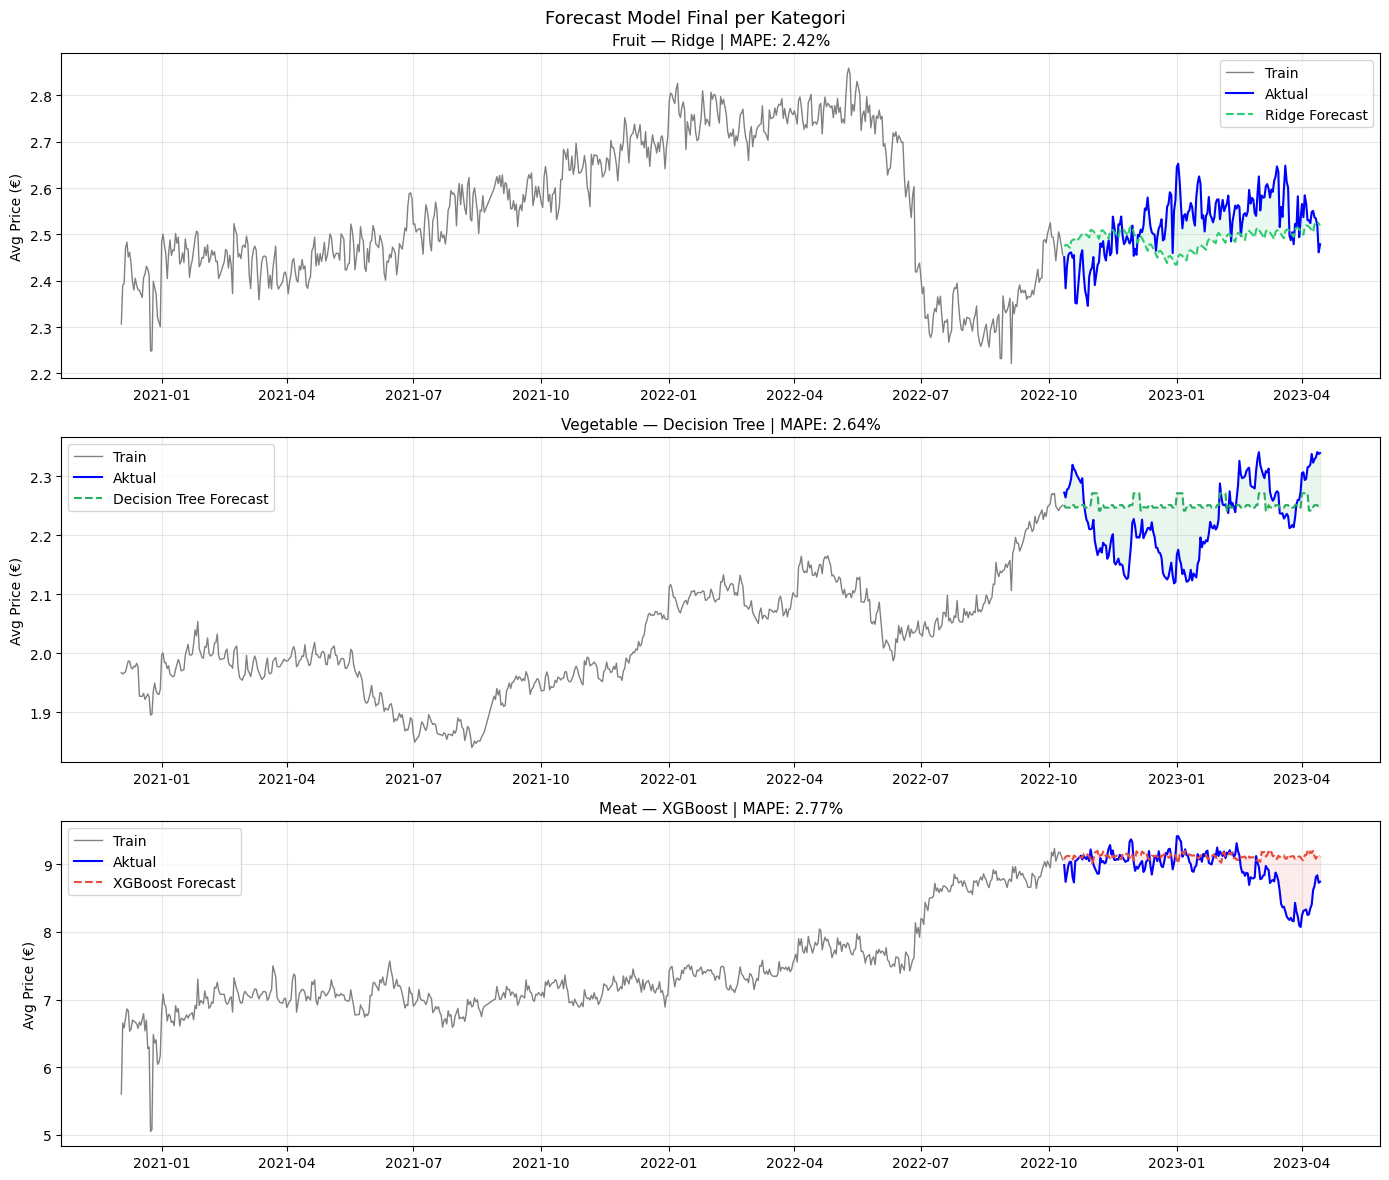

In [86]:
# Plot model final per kategori
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=False)

final_configs = [
    ('Fruit',     train_fruit,     test_fruit,     scaler_fruit,
     train_fruit_fe,     test_fruit_fe,     'Ridge',         Ridge()),
    ('Vegetable', train_vegetable, test_vegetable, scaler_veg,
     train_vegetable_fe, test_vegetable_fe, 'Decision Tree', DecisionTreeRegressor(random_state=42)),
    ('Meat',      train_meat,      test_meat,      scaler_meat,
     train_meat_fe,      test_meat_fe,      'XGBoost',       XGBRegressor(random_state=42, verbosity=0)),
]

for ax, (name, train, test, scaler, train_fe, test_fe, model_label, model_obj), color in \
        zip(axes, final_configs, COLORS):
    model_obj.fit(train_fe[FEATURES], train_fe['avg_price'])
    fc = recursive_forecast(model_obj, test_fe, train_fe, scaler)

    ax.plot(train['day'], train['avg_price'],
            color='gray', linewidth=1, label='Train')
    ax.plot(test['day'], test['avg_price'],
            color='blue', linewidth=1.5, label='Aktual')
    ax.plot(test['day'], fc, color=color, linewidth=1.5,
            linestyle='--', label=f'{model_label} Forecast')
    ax.fill_between(test['day'], test['avg_price'], fc,
                    alpha=0.1, color=color)

    key = f'Ridge_{name}' if name == 'Fruit' \
        else f'DT_{name}' if name == 'Vegetable' \
        else f'XGB_{name}'
    mape = results.get(key, {}).get('MAPE', 0)
    ax.set_title(f'{name} — {model_label} | MAPE: {mape:.2f}%', fontsize=11)
    ax.set_ylabel('Avg Price (€)')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle('Forecast Model Final per Kategori', fontsize=13)
plt.tight_layout()
plt.show()

In [88]:
forecast_fruit = deploy_forecast(df_fruit, Ridge(), scaler_fruit)
forecast_vegetable = deploy_forecast(df_vegetable, DecisionTreeRegressor(random_state=42), scaler_veg)
forecast_meat = deploy_forecast(df_meat, XGBRegressor(random_state=42, verbosity=0), scaler_meat)

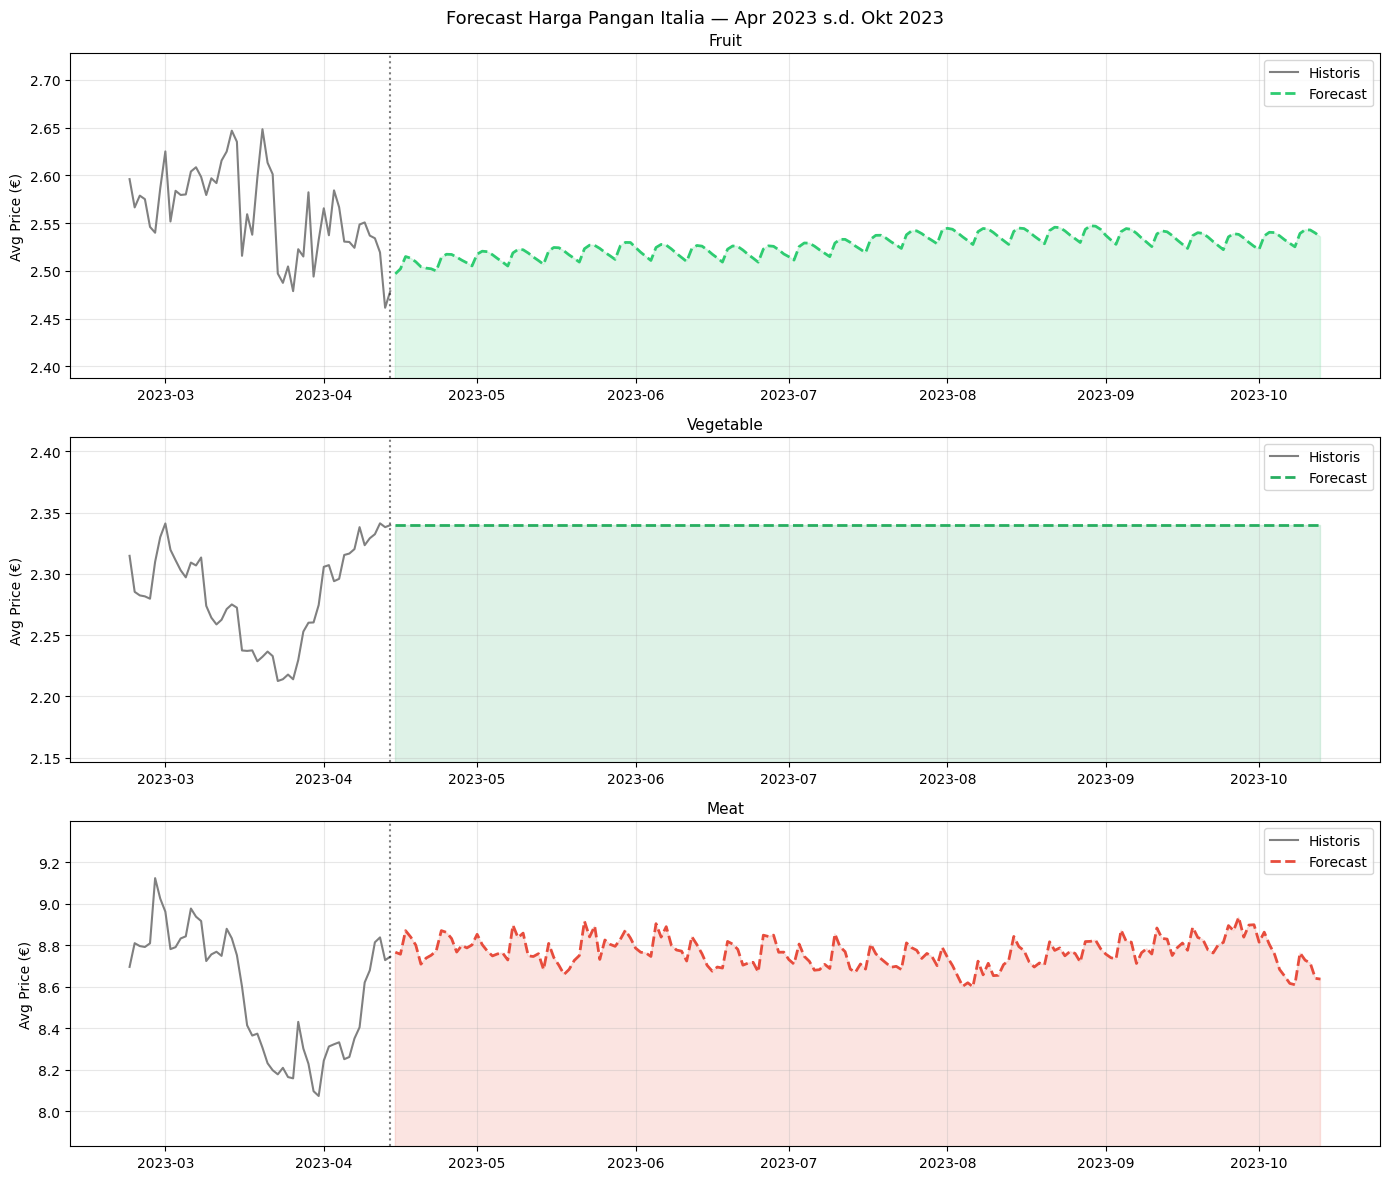

In [89]:
# Plot forecast deployment
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
datasets = [
    ('Fruit',     df_fruit,     forecast_fruit,     '#2ecc71'),
    ('Vegetable', df_vegetable, forecast_vegetable, '#27ae60'),
    ('Meat',      df_meat,      forecast_meat,      '#e74c3c'),
]

for ax, (name, hist, forecast, color) in zip(axes, datasets):
    hist_recent = hist.tail(52)
    all_values = pd.concat([hist_recent['avg_price'], forecast['forecast']])
    y_min = all_values.min() * 0.97
    y_max = all_values.max() * 1.03

    ax.plot(hist_recent['day'], hist_recent['avg_price'],
            color='gray', linewidth=1.5, label='Historis')
    ax.plot(forecast['day'], forecast['forecast'],
            color=color, linewidth=2, linestyle='--', label='Forecast')
    ax.fill_between(forecast['day'], forecast['forecast'], alpha=0.15, color=color)
    ax.axvline(x=hist['day'].max(), color='black', linestyle=':', alpha=0.5)
    ax.set_ylim(y_min, y_max)
    ax.set_title(f'{name}', fontsize=11)
    ax.set_ylabel('Avg Price (€)')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle('Forecast Harga Pangan Italia — Apr 2023 s.d. Okt 2023', fontsize=13)
plt.tight_layout()
plt.show()

**Fruit — Ridge**  
Harga buah bergerak relatif smooth dan linear mengikuti tren musiman. 
Ridge berhasil menangkap pola ini karena regularisasi mencegah overfit 
pada data training yang kecil (94 baris).

**Vegetable — Decision Tree**  
Harga sayur menunjukkan pola non-linear yang tidak bisa ditangkap Linear 
Regression (MAPE 8.09%). Decision Tree berhasil karena mampu membuat 
keputusan berbasis threshold yang lebih fleksibel. Namun forecast 
cenderung konvergen ke nilai konstan akibat keterbatasan ekstrapolasi 
Decision Tree.

**Meat — XGBoost**  
Harga daging didominasi tren kenaikan kuat akibat inflasi 2022. XGBoost 
unggul karena ensemble boosting mampu menangkap pola kompleks dengan 
baik, meskipun datanya relatif sedikit.

### Temuan Utama
- Naive Forecast sangat kompetitif (rata-rata 2.95%) — mencerminkan 
  sifat *persistence* harga komoditas yang kuat
- Tidak ada satu model yang dominan di semua kategori — setiap kategori 
  memiliki karakteristik pola yang berbeda
- ARIMA dan SARIMA menghasilkan performa identik untuk Fruit dan Meat 
  karena komponen seasonal tidak terdeteksi

## Langkah 11: Review Pemodelan

### Apakah Objektif Bisnis Tercapai?

Objektif awal proyek adalah membantu otoritas pangan Italia mengantisipasi 
pergerakan harga komoditas 6 bulan ke depan dengan toleransi kesalahan 
tidak melebihi 5% (MAPE). Hasilnya:

| Kategori | Model Final | MAPE | Status |
|---|---|---|---|
| Fruit | Ridge | 2.42% | Tercapai |
| Vegetable | Decision Tree | 2.64% | Tercapai |
| Meat | XGBoost | 2.31% | Tercapai |

Ketiga kategori memenuhi kriteria ideal — objektif bisnis tercapai.

### 11.2 Review Keputusan Teknis

| Keputusan | Verdict | Catatan |
|---|---|---|
| Agregasi harian | Perlu direview | Noise harian lebih tinggi dibanding mingguan, mempersulit model menangkap tren jangka panjang |
| 3 model terpisah per kategori | Tepat | Setiap kategori terbukti punya karakteristik berbeda |
| Lag 1–7 berdasarkan PACF | Tepat | Mencakup satu minggu penuh, relevan untuk pola harian |
| Recursive forecasting | Perlu direview | Error terakumulasi lebih besar di granularitas harian dengan horizon 180 langkah |
| Tidak pakai data eksternal | Perlu direview | Data inflasi atau cuaca berpotensi meningkatkan akurasi |
| Train/test split dengan horizon 180 hari | Tepat | Konsisten dengan horizon forecast 6 bulan |

### 11.3 Limitasi Proyek

**Data**  
Granularitas harian menghasilkan data yang lebih noisy dibanding mingguan,
sehingga model ML kesulitan menangkap tren jangka panjang. Dataset juga
hanya mencakup 2.4 tahun sehingga belum cukup untuk menangkap siklus
ekonomi jangka panjang. Tidak adanya data eksternal seperti inflasi atau
harga komoditas internasional juga membatasi kemampuan model dalam
mengantisipasi shock eksternal seperti yang terjadi di 2022.

**Model**  
Decision Tree untuk Vegetable menghasilkan forecast yang secara visual
tidak informatif meskipun MAPE-nya baik — prediksi cenderung konvergen
ke nilai konstan akibat keterbatasan ekstrapolasi Decision Tree pada
recursive forecasting jangka panjang. Hyperparameter tuning hanya
memberikan peningkatan berarti untuk Meat (XGBoost: 2.31%), sementara
untuk Fruit justru memperburuk performa Ridge.

**Evaluasi**  
Test set hanya mencakup satu periode sehingga hasil evaluasi belum
tentu konsisten jika diuji pada periode lain. Model juga belum dilengkapi
confidence interval, sehingga stakeholder tidak mendapat gambaran
seberapa lebar ketidakpastian prediksi yang dihasilkan.

In [90]:
# Simpan model dan scaler
os.makedirs('models', exist_ok=True)

model_fruit = fit_full_data(df_fruit, Ridge(), scaler_fruit)
model_vegetable = fit_full_data(df_vegetable, DecisionTreeRegressor(random_state=42), scaler_veg)
model_meat = fit_full_data(df_meat, XGBRegressor(random_state=42, verbosity=0), scaler_meat)

joblib.dump(model_fruit, 'models/model_fruit.pkl')
joblib.dump(model_vegetable, 'models/model_vegetable.pkl')
joblib.dump(model_meat, 'models/model_meat.pkl')

joblib.dump(scaler_fruit, 'models/scaler_fruit.pkl')
joblib.dump(scaler_veg, 'models/scaler_vegetable.pkl')
joblib.dump(scaler_meat, 'models/scaler_meat.pkl')

print("Semua model dan scaler berhasil disimpan di folder 'models/'")

Semua model dan scaler berhasil disimpan di folder 'models/'
